# Weekly A&E demand and escalation briefing: spot check

## 1. Purpose, scope and what is simulated

This notebook is the spot check behind the design case study: the design run on Public Health
Scotland's real weekly A&E data. It loads and checks the data,
forecasts demand, runs the demand level and drift rules, and evaluates them. Sections 5 to 7, the
agents, the approval queue and the replay set, replay the live runs' recorded model replies; no
language model runs in this notebook.

**Status: additional information only.** At this stage the system gives the duty manager additional
information beside their existing process. It replaces no current process and sets no staffing on its
own. Becoming a primary operational tool needs shadow mode, a pilot and tuning over time, which is
achievable but not yet done.

**What the drift latch is.** The drift alarm fires when a series' actual attendances fall outside the
range its forecast expected for two released weeks running. Once it fires, the drift latch stays set,
like an alarm that stays on until someone resets it. While it is set, the forecasts are marked
untrusted, and only a person can reset it.

**What the demand level means.** The demand level shows demand unusually high for the time of year.
It is not pressure, need or priority. It is for adjusting front-door staffing inside rotas already
set: extra shifts, bank staff or holding leave.

**What the tool is for.** Aggregate operational planning for a hospital and a week. It is never for
ranking hospitals, justifying cuts or monitoring the 4-hour standard, and a person approves every
action it suggests.

| Input | Real or simulated | Where it comes from |
|---|---|---|
| Weekly unplanned attendances per hospital, and their national sum | Real | Public Health Scotland, weekly A&E activity, frozen by SHA-256, OGL |
| Attendances seen within 4 hours, and waits over 12 hours | Real | The same file; used only for the pressure match and the month chart, never to monitor the 4-hour standard |
| Scottish bank holidays | Real | GOV.UK bank-holidays JSON, frozen 24 Oct 2026, OGL |
| Simulated capacity | Simulated | Assumed: the 90th percentile of each hospital's own past demand in the same 13 weeks of the three previous years. A seasonal baseline of past demand, not beds or staff |
| The bands, 1.05, 1.10 and 1.15 times capacity | Our design, illustrative | Assumed: the structure of England's OPEL framework, where a score sets the level and people decide the actions, not its scale |
| Latch resets | Simulated | Assumed: recorded at each review prompt after 8 clear weeks, as the replay does; in use the unscheduled-care lead approves each one |
| The staffing actions by level and their reply deadlines | Our design, illustrative | Assumed: on the structure of OPEL Appendix F only, actions by level with an owner each, not its pressure actions; the deadlines are assumed |
| Staff acknowledgements of notifications | Simulated | Assumed: seeded stand-ins, not real replies, on the replay's clock, which starts at 10:00 on release day |
| The model's replies in sections 5 to 7 | Recorded | The live run's recordings, replayed exactly; no model runs in this notebook |

Every figure in this notebook is in-sample: the design was tuned in design probes on the same 2015
to 2026 data that scores it.

![Figure 1: code decides, the agents explain, a person approves](figures/fig1_architecture.png)

*Figure 1. Code decides, the agents explain, a person approves.* Each box names the prior project it
comes from or says it is new, and each numbered arrow is a row of the case study's interaction table.

![Figure 2: the value chain, each link with its evidence label](figures/fig2_value_chain.png)

*Figure 2. The value chain: measured, sourced, to be tested.* Link 1's figures come from section 8.

In [1]:
# The Environment Setup tab's import check: NumPy, pandas and Matplotlib.
import json
import sys
import tempfile
import textwrap
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydantic
import torch
from IPython.display import display
from pydantic import ValidationError

from ae_escalation import approval as ap
from ae_escalation import backtest as bt
from ae_escalation import briefs as br
from ae_escalation import config as cf
from ae_escalation import coordinator as co
from ae_escalation import data as dt
from ae_escalation import demo as dm
from ae_escalation import design as ds
from ae_escalation import evaluation as ev
from ae_escalation import gru
from ae_escalation import replay as rp
from ae_escalation import template as tp
from ae_escalation import timing as tm
from ae_escalation import tools as tl
from ae_escalation import units as un

print("Python", sys.version.split()[0])
print("NumPy", np.__version__)
print("pandas", pd.__version__)
print("Matplotlib", matplotlib.__version__)
print("torch", torch.__version__, "and Pydantic", pydantic.__version__)

Python 3.12.3
NumPy 2.5.4
pandas 3.0.6
Matplotlib 3.11.2
torch 2.14.1+cpu and Pydantic 2.14.1


In [2]:
DATA = Path("data")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
NAMES = {**dt.HOSPITAL_NAMES, "Scotland": "Scotland"}
BIG5 = ["S314H", "G405H", "G107H", "L308H", "F704H"]
REPLAY = list(ds.REPLAY)
MODEL_NAMES = {
    "seasonal_naive": "Seasonal naive",
    "ma4": "4-week moving average",
    "linear": "Linear",
    "gru": "GRU comparator",
    "naive_last_week": "Reference: last week's value",
    "linear_covid_masked": "Reference: linear, COVID weeks left out",
}
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", None)

# Neutral inks for text and axes; blue and orange are the first two slots
# of a palette checked for colour-blind readers.
INK, MUTED, GRID, BAND = "#0b0b0b", "#52514e", "#d8d7d2", "#ecebe7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 10,
    }
)


def ci_cell(value, low, high):
    return f"{value:.2f} ({low:.2f} to {high:.2f})"

## 2. Data: load, verify, clean, flag

I follow the pattern AI Programming Foundations taught: load, verify, clean, flag and keep. The file
is checked against the SHA-256 in the manifest before it is read. Every row stays in the flagged
frame; a row left out of the series carries its reason, so it can still be counted and reported.
The series is weekly Unplanned attendances from the week ending 7 June 2015, after the
reconfiguration of Glasgow's emergency departments in May 2015.

In [3]:
manifest = {r.file: r for r in dt.read_manifest(DATA / "MANIFEST.tsv")}
sources = dt.verify_sources(DATA / "MANIFEST.tsv")
sources[["file", "licence", "access date", "bytes", "matches"]]

,file,licence,access date,bytes,matches
0,weekly_ae_activity_20261011.csv,UK Open Government Licence (OGL),2026-10-24,3829935,True
1,bank-holidays_20261024.json,Open Government Licence (OGL),2026-10-24,22207,True


In [4]:
CSV = "weekly_ae_activity_20261011.csv"
raw = dt.load_weekly(DATA / CSV, manifest[CSV].sha256)
quality = dt.quality_report(raw)
shape = {
    "rows": len(raw),
    "week endings": raw["WeekEndingDate"].nunique(),
    "first week ending": f"{raw['WeekEndingDate'].min():%d %b %Y}",
    "last week ending": f"{raw['WeekEndingDate'].max():%d %b %Y}",
    "hospitals": raw["TreatmentLocation"].nunique(),
    "health boards": raw["HBT"].nunique(),
}
pd.Series({**shape, **quality}, name="value").to_frame()

,value
rows,43185
week endings,608
first week ending,22 Feb 2015
last week ending,11 Oct 2026
hospitals,32
health boards,14
missing_values,0
duplicate_key_rows,2
duplicate_keys,"[(2015-05-03, G405H)]"
unplanned_zero_attendances,0


In [5]:
flagged = dt.flag_and_keep(raw)
in_series = flagged["in_series"]
print(
    f"{len(flagged):,} rows in the flagged frame: {in_series.sum():,} in the "
    f"series and {(~in_series).sum():,} set aside, each with its reason"
)
display(
    flagged.loc[~in_series, "exclusion_reason"]
    .value_counts()
    .rename("rows set aside")
    .to_frame()
)
unplanned = flagged[flagged["AttendanceCategory"] == "Unplanned"]
flags = ["duplicate_key", "site_outlier", "covid_period", "provisional"]
unplanned[flags].sum().rename("Unplanned rows flagged and kept").to_frame()

43,185 rows in the flagged frame: 17,790 in the series and 25,395 set aside, each with its reason


,rows set aside
exclusion_reason,
"not the Unplanned category, which is the series",24916
"before w/e 7 Jun 2015, the series' first week",479


,Unplanned rows flagged and kept
duplicate_key,2
site_outlier,48
covid_period,3270
provisional,90


In [6]:
wide = dt.series_from(flagged)
within4 = dt.series_from(flagged, value_col="NumberWithin4HoursEpisode")
sites = [c for c in wide.columns if c != "Scotland"]
print(
    f"{len(sites)} hospitals and the national series, {len(wide)} weeks from "
    f"w/e {wide.index[0]:%d %b %Y} to w/e {wide.index[-1]:%d %b %Y}; "
    f"no week missing: {bool(wide.notna().all().all())}"
)
national_all = dt.to_wide(raw, "TreatmentLocation").sum(axis=1)
outliers = dt.national_outliers(raw)
national_all[outliers].rename("national attendances").rename_axis(
    "national week flagged as an outlier and kept"
).to_frame()

30 hospitals and the national series, 593 weeks from w/e 07 Jun 2015 to w/e 11 Oct 2026; no week missing: True


,national attendances
national week flagged as an outlier and kept,
2016-12-25,22251.0
2017-12-17,29061.0
2018-03-04,21752.0
2020-03-29,11012.0
2020-04-05,11274.0
2020-04-12,11887.0
2021-12-26,18993.0
2023-01-15,20484.0
2025-12-28,22626.0


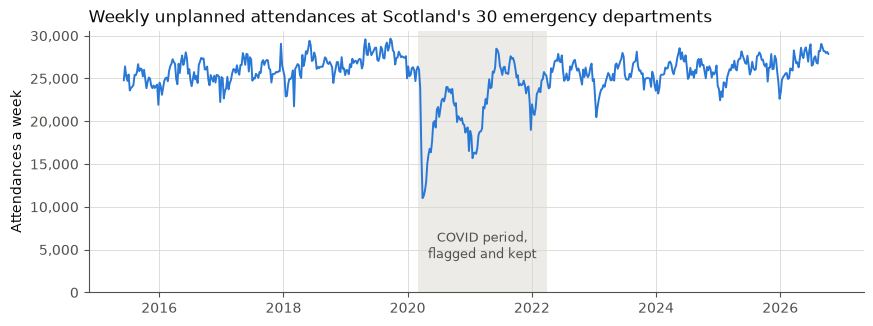

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.axvspan(*dt.COVID_PERIOD, color=BAND, lw=0)
ax.plot(wide.index, wide["Scotland"], color=BLUE, lw=1.4)
ax.text(
    pd.Timestamp("2021-03-15"),
    4000,
    "COVID period,\nflagged and kept",
    color=MUTED,
    ha="center",
    fontsize=9,
)
ax.set_title(
    "Weekly unplanned attendances at Scotland's 30 emergency departments",
    loc="left",
    color=INK,
)
ax.set_ylabel("Attendances a week")
ax.set_ylim(0, None)
ax.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
fig.savefig(
    FIGURES / "national_weekly_attendances.png", dpi=150, bbox_inches="tight"
)
plt.show()

**What is flagged and kept.** Nothing above is dropped from the file's frame. The weeks before
7 June 2015 and the two Glasgow sites that closed in May 2015 are set aside from the series with
their reason. One week at the Queen Elizabeth University Hospital, w/e 3 May 2015, has two rows per
category, which are summed, and it is before the series starts. The `All` category gains planned
attendances from November 2020, so the series is `Unplanned`, which continues the series as
published before 2025. The COVID period, March 2020 to March 2022, stays in the data, so the drift
latch and the re-selection are tested on a real shock; it is used only to split what is reported.
The newest three weeks are flagged provisional, because in my data test PHS revised its latest week
or two slightly upward. The
outlier weeks stay in: three are Christmas weeks, which is why a demand brief names a bank holiday
that falls in a target week.

In [8]:
# The scale the value case quotes: every attendance at the emergency
# departments in the weekly data, weeks ending in 2025, all and unplanned.
in_2025 = raw[raw["WeekEndingDate"].dt.year == 2025]
totals = {
    c: in_2025.loc[
        in_2025["AttendanceCategory"] == c, "NumberOfAttendancesEpisode"
    ].sum()
    for c in ("All", "Unplanned")
}
print(
    f"Weeks ending in 2025: {in_2025['WeekEndingDate'].nunique()}, at "
    f"{in_2025['TreatmentLocation'].nunique()} emergency departments; all "
    f"attendances {totals['All']:,}, unplanned {totals['Unplanned']:,}"
)

Weeks ending in 2025: 52, at 30 emergency departments; all attendances 1,405,613, unplanned 1,359,889


## 3. Forecasts and back-test

**Timing.** Each Tuesday release covers the week ending 9 days earlier. A forecast origin is the
latest week released, and the four release horizons are the next four week endings after the
release, which are data horizons 2 to 5. Every forecast, rule and tool works as of an origin and
sees only the weeks released by then; a unit test proves it.

In [9]:
origin = pd.Timestamp("2020-03-22")
print(
    f"Origin w/e {origin:%a %d %b %Y}, released "
    f"{tm.release_date(origin):%a %d %b %Y}"
)
pd.DataFrame(
    {
        "release horizon": tm.RELEASE_HORIZONS,
        "data horizon": [tm.data_horizon(k) for k in tm.RELEASE_HORIZONS],
        "week ending": tm.release_horizon_weeks(origin).strftime(
            "%a %d %b %Y"
        ),
    }
).set_index("release horizon")

Origin w/e Sun 22 Mar 2020, released Tue 31 Mar 2020


,data horizon,week ending
release horizon,,
1,2,Sun 05 Apr 2020
2,3,Sun 12 Apr 2020
3,4,Sun 19 Apr 2020
4,5,Sun 26 Apr 2020


![Figure 3: one week, from the week's end to the duty manager's decision](figures/fig3_weekly_cycle.png)

*Figure 3. One week: Tuesday release to the duty manager's decision.* The dates illustrate the release timing for
one replay week, Ninewells Hospital's demand week ending 13 Jun 2021; that week's brief was rejected.

**The back-test** is the rolling-origin back-test of the data test, fixed before any result was
seen, so its figures reproduce: an origin every week, MAPE scored from w/e 7 January
2018, and 95% moving-block bootstrap intervals (8-week blocks, 2,000 resamples). Seasonal naive and
the 4-week moving average are the bars to beat from Deep Learning Systems. Linear is the trend line
from Statistical Analysis with four sine and cosine pairs, refitted at each origin on the trailing
156 weeks. The GRU comparator is Deep Learning Systems' recurrent forecaster: one layer of 16 units,
refitted each January, early stopping on the last 26 windows and the mean of three seeds, on the CPU.
The two reference rows are the data test's own: last week's value, and linear with the COVID weeks
left out, which uses hindsight. These first tables are at the data test's data horizons 1 to 4.

In [10]:
cal = tm.complete_weeks(wide.index[0], wide.index[-1] + pd.Timedelta(weeks=4))
baselines = bt.backtest_long(wide, bt.data_test_models(cal), H=4)
# The data test ran its GRU on six series; the design runs the GRU on the
# five named series only, so the three both share are reproduced here.
gru_dt = gru.gru_long(
    wide, ["Scotland", "S314H", "G405H"], H=4, first_target=bt.SCORE_START
)
backtest = pd.concat([baselines, gru_dt], ignore_index=True)
periods = bt.data_test_periods(backtest)
metrics = bt.error_summary(backtest, periods, series=["Scotland", *BIG5])


def mape_table(period, series="Scotland"):
    t = metrics[(metrics["period"] == period) & (metrics["series"] == series)]
    t = t.assign(
        cell=[ci_cell(*v) for v in t[["mape", "mape_lo", "mape_hi"]].values]
    )
    out = t.pivot(index="model", columns="h", values="cell")
    order = [m for m in MODEL_NAMES if m in out.index]
    return (
        out.loc[order]
        .rename(index=MODEL_NAMES)
        .rename(columns=lambda h: f"data horizon {h}")
    )


print("National MAPE %, 95% interval, outside March 2020 to March 2022")
mape_table("excl_covid")

National MAPE %, 95% interval, outside March 2020 to March 2022


h,data horizon 1,data horizon 2,data horizon 3,data horizon 4
model,,,,
Seasonal naive,3.77 (3.22 to 4.35),3.77 (3.22 to 4.35),3.77 (3.22 to 4.35),3.77 (3.22 to 4.35)
4-week moving average,3.17 (2.79 to 3.52),3.70 (3.23 to 4.13),4.10 (3.59 to 4.60),4.42 (3.87 to 4.95)
Linear,3.82 (3.06 to 4.75),4.05 (3.22 to 5.07),4.25 (3.36 to 5.32),4.41 (3.47 to 5.56)
GRU comparator,3.51 (2.98 to 4.16),3.62 (2.92 to 4.50),3.19 (2.79 to 3.64),3.77 (3.18 to 4.45)
Reference: last week's value,2.71 (2.42 to 3.00),3.66 (3.25 to 4.04),4.00 (3.50 to 4.44),4.35 (3.80 to 4.89)
"Reference: linear, COVID weeks left out",3.12 (2.63 to 3.67),3.28 (2.74 to 3.89),3.40 (2.81 to 4.07),3.50 (2.86 to 4.21)


In [11]:
print("National MAPE %, 95% interval, all weeks from w/e 7 Jan 2018")
mape_table("all")

National MAPE %, 95% interval, all weeks from w/e 7 Jan 2018


h,data horizon 1,data horizon 2,data horizon 3,data horizon 4
model,,,,
Seasonal naive,10.94 (7.28 to 15.34),10.94 (7.28 to 15.34),10.94 (7.28 to 15.34),10.94 (7.28 to 15.34)
4-week moving average,4.25 (3.34 to 5.56),5.27 (4.02 to 7.09),6.10 (4.60 to 8.26),6.81 (5.11 to 9.33)
Linear,8.03 (5.52 to 11.51),8.57 (5.88 to 12.28),9.04 (6.18 to 12.98),9.44 (6.45 to 13.60)
GRU comparator,8.00 (5.29 to 11.72),8.50 (5.64 to 12.39),7.67 (4.98 to 11.39),7.96 (5.29 to 11.74)
Reference: last week's value,3.17 (2.74 to 3.74),4.56 (3.73 to 5.76),5.38 (4.17 to 7.11),6.26 (4.73 to 8.47)
"Reference: linear, COVID weeks left out",10.64 (6.60 to 15.41),10.76 (6.70 to 15.52),10.85 (6.80 to 15.63),10.94 (6.89 to 15.72)


In [12]:
sub = metrics[(metrics["series"] == "Scotland") & metrics["h"].isin([1, 4])]
labels = {
    "pre_2018_feb2020": "Jan 2018 to Feb 2020",
    "covid_mar2020_mar2022": "Mar 2020 to Mar 2022",
    "post_apr2022_oct2026": "Apr 2022 to Oct 2026",
}
sub = sub[sub["period"].isin(labels)].pivot(
    index="model", columns=["period", "h"], values="mape"
)
print("National MAPE % by sub-period, data horizons 1 and 4")
display(
    sub.loc[[m for m in MODEL_NAMES if m in sub.index]]
    .rename(index=MODEL_NAMES, columns=labels)
    .round(2)
)
pairs = bt.paired_against(
    backtest,
    "seasonal_naive",
    {"excl_covid": periods["excl_covid"]},
    series=["Scotland"],
)
pairs = pairs[pairs["h"].isin([1, 4])].assign(
    difference=lambda p: [
        f"{d:+.2f} ({lo:+.2f} to {hi:+.2f})"
        for d, lo, hi in p[["mean_diff", "lo", "hi"]].values
    ]
)
print(
    "Paired difference in absolute % error against seasonal naive, national, "
    "outside the COVID period (negative is better)"
)
pairs.pivot(index="model", columns="h", values="difference").reindex(
    [m for m in MODEL_NAMES if m in set(pairs["model"])]
).rename(index=MODEL_NAMES, columns=lambda h: f"data horizon {h}")

National MAPE % by sub-period, data horizons 1 and 4


period                                  Jan 2018 to Feb 2020       Mar 2020 to Mar 2022        Apr 2022 to Oct 2026      
h                                                          1     4                    1      4                    1     4
model                                                                                                                    
Seasonal naive                                          4.17  4.17                33.90  33.90                 3.58  3.58
4-week moving average                                   3.04  3.79                 7.71  14.46                 3.23  4.72
Linear                                                  2.71  2.94                21.52  25.55                 4.34  5.11
GRU comparator                                          3.12  2.99                22.37  21.36                 3.69  4.14
Reference: last week's value                            2.74  3.99                 4.66  12.36                 2.69  4.52
Reference: linear, COVID weeks left out                 2.71  2.94                34.71  34.73                 3.32  3.77

Paired difference in absolute % error against seasonal naive, national, outside the COVID period (negative is better)


h,data horizon 1,data horizon 4
model,,
4-week moving average,-0.60 (-1.27 to -0.02),+0.65 (-0.15 to +1.36)
Linear,+0.05 (-0.86 to +1.06),+0.65 (-0.42 to +1.84)
GRU comparator,-0.26 (-0.89 to +0.40),+0.00 (-0.70 to +0.77)
Reference: last week's value,-1.06 (-1.67 to -0.51),+0.58 (-0.22 to +1.26)
"Reference: linear, COVID weeks left out",-0.65 (-1.24 to -0.10),-0.27 (-0.97 to +0.42)


In [13]:
five = metrics[
    (metrics["period"] == "excl_covid")
    & metrics["series"].isin(BIG5)
    & metrics["h"].isin([1, 4])
].pivot(index="series", columns=["model", "h"], values="mape")
five.index = [f"{NAMES[s]} ({s})" for s in five.index]
print(
    "Five large adult EDs, MAPE % at data horizons 1 and 4, outside the "
    "COVID period. The GRU runs only on the two of them in the replay set."
)
five = five.reindex(columns=list(MODEL_NAMES), level=0)
display(five.round(2).rename(columns=MODEL_NAMES, level=0))
sizes = bt.site_sizes(wide)
bands, size_corr = bt.size_bands(backtest, sizes, periods["excl_covid"])
print(
    f"Correlation of log size with log seasonal naive MAPE at horizon 1: "
    f"{size_corr:.2f}"
)
bands.round(1)

Five large adult EDs, MAPE % at data horizons 1 and 4, outside the COVID period. The GRU runs only on the two of them in the replay set.


model                                                 Seasonal naive       4-week moving average       Linear        \
h                                                                  1     4                     1     4      1     4   
Victoria Hospital (F704H)                                       6.02  6.02                  3.77  4.95   4.85  5.50   
Glasgow Royal Infirmary (G107H)                                 4.94  4.94                  3.71  4.39   4.89  5.58   
Queen Elizabeth University Hospital (G405H)                     4.62  4.62                  3.11  3.75   3.81  4.22   
University Hospital Wishaw (L308H)                              5.84  5.84                  3.96  5.08   4.78  5.41   
Royal Infirmary of Edinburgh at Little France (S314H)           4.46  4.46                  2.86  3.65   3.65  4.20   

model                                                 GRU comparator       Reference: last week's value        \
h                                                                  1     4                            1     4   
Victoria Hospital (F704H)                                        NaN   NaN                         3.82  5.17   
Glasgow Royal Infirmary (G107H)                                  NaN   NaN                         3.94  4.83   
Queen Elizabeth University Hospital (G405H)                     3.55  3.38                         3.51  3.98   
University Hospital Wishaw (L308H)                               NaN   NaN                         4.06  5.40   
Royal Infirmary of Edinburgh at Little France (S314H)           3.72  3.31                         3.12  3.95   

model                                                 Reference: linear, COVID weeks left out        
h                                                                                           1     4  
Victoria Hospital (F704H)                                                                4.27  4.66  
Glasgow Royal Infirmary (G107H)                                                          4.69  5.34  
Queen Elizabeth University Hospital (G405H)                                              4.46  5.03  
University Hospital Wishaw (L308H)                                                       4.66  5.21  
Royal Infirmary of Edinburgh at Little France (S314H)                                    3.59  4.07

Correlation of log size with log seasonal naive MAPE at horizon 1: -0.89


,band,sites,mean_weekly_range,seasonal_naive_h1_median,seasonal_naive_h4_median,linear_h1_median,linear_h4_median,ma4_h1_median,ma4_h4_median,poisson_floor_pct
0,under 300,7,112 to 268,11.0,11.0,8.9,9.6,8.7,9.8,6.0
1,300 to 799,8,343 to 757,8.0,8.0,6.3,7.1,5.2,6.5,3.3
2,"800 to 1,299",9,1031 to 1254,5.5,5.5,5.1,5.7,4.2,5.1,2.3
3,"1,300 and over",6,1333 to 2363,5.4,5.4,4.8,5.5,3.7,4.7,2.1


In [14]:
failure = bt.failure_case(backtest, "Scotland", "2020-03-08")
failure = failure.assign(
    cell=[
        f"{f:,.0f} ({a:.1f}%)" for f, a in failure[["forecast", "ape"]].values
    ]
)
table = failure.pivot(index="target", columns="model", values="cell")
table = table[[m for m in MODEL_NAMES if m in table.columns]]
table.insert(
    0,
    "actual",
    failure.groupby("target")["actual"].first().map("{:,.0f}".format),
)
print(
    "The failure case: national forecasts made at w/e 8 Mar 2020, with "
    "their absolute % errors"
)
table.rename(columns=MODEL_NAMES)

The failure case: national forecasts made at w/e 8 Mar 2020, with their absolute % errors


model,actual,Seasonal naive,4-week moving average,Linear,GRU comparator,Reference: last week's value,"Reference: linear, COVID weeks left out"
target,,,,,,,
2020-03-15,"23,950","27,105 (13.2%)","25,782 (7.6%)","27,512 (14.9%)","27,691 (15.6%)","26,042 (8.7%)","27,725 (15.8%)"
2020-03-22,"16,394","27,296 (66.5%)","25,782 (57.3%)","27,692 (68.9%)","27,694 (68.9%)","26,042 (58.9%)","27,874 (70.0%)"
2020-03-29,"11,012","27,237 (147.3%)","25,782 (134.1%)","27,842 (152.8%)","27,767 (152.2%)","26,042 (136.5%)","27,981 (154.1%)"
2020-04-05,"11,274","26,175 (132.2%)","25,782 (128.7%)","27,989 (148.3%)","27,668 (145.4%)","26,042 (131.0%)","28,079 (149.1%)"


**The design at the release horizons.** From here the models run as the design runs them, one
origin at a time: linear starts as the primary model for every series, and at each latch reset the
primary is re-selected for that series among seasonal naive, the 4-week moving average, linear and
SA-MA, by MAPE at release horizon 2 on the latest 104 released weeks. SA-MA is the 4-week moving
average with a seasonal index by ISO week from the latest three complete calendar years, reaching
back up to 8 years past latched weeks; both choices were settled after a first run in the design
probes, so they are in-sample, and the 52-week-block version runs beside it as a sensitivity.

In [15]:
run = ds.run_design(wide)
run_blocks = ds.run_design(wide, blocks=True)
frame = run.frame
print(
    f"{frame['series'].nunique()} series, {len(run.weeks)} origins each, "
    f"{len(frame):,} outlooks"
)

31 series, 593 origins each, 18,383 outlooks


In [16]:
gru_rh = gru.gru_long(wide, REPLAY, H=5, first_target=bt.SCORE_START)
versus = ev.gru_against_primary(run, gru_rh, REPLAY)


def reading(low, high):
    if high < 0:
        return "favours the GRU"
    if low > 0:
        return "favours the primary"
    return "no measurable gain"


versus["GRU minus primary"] = [
    f"{d:+.2f} ({lo:+.2f} to {hi:+.2f})"
    for d, lo, hi in versus[["gru_minus_primary", "lo", "hi"]].values
]
versus["reading"] = [reading(lo, hi) for lo, hi in versus[["lo", "hi"]].values]
versus["series"] = versus["series"].map(NAMES)
cols = [
    "series",
    "release_horizon",
    "n",
    "mape_primary",
    "mape_seasonal naive",
    "mape_4-week moving average",
    "mape_linear",
    "mape_SA-MA",
    "mape_gru",
    "GRU minus primary",
    "reading",
]
print(
    "MAPE % at the release horizons from w/e 7 Jan 2018, outside each "
    "series' drift episodes, as G1 scores the national series"
)
display(versus[versus["scope"] == "outside drift episodes"][cols].round(2))
print(
    "The same outside March 2020 to March 2022, the data test's window: GRU "
    "and primary only"
)
window = versus[versus["scope"] == "outside March 2020 to March 2022"]
window[
    [
        "series",
        "release_horizon",
        "n",
        "mape_primary",
        "mape_gru",
        "GRU minus primary",
        "reading",
    ]
].round(2)

MAPE % at the release horizons from w/e 7 Jan 2018, outside each series' drift episodes, as G1 scores the national series


,series,release_horizon,n,mape_primary,mape_seasonal naive,mape_4-week moving average,mape_linear,mape_SA-MA,mape_gru,GRU minus primary,reading
1,Scotland,1,441,4.04,9.19,4.22,6.86,3.47,6.51,+2.46 (+1.26 to +3.87),favours the primary
4,Scotland,2,441,4.52,9.19,4.89,7.24,3.85,7.22,+2.70 (+1.24 to +4.45),favours the primary
7,Scotland,3,441,4.94,9.19,5.49,7.58,4.20,7.97,+3.03 (+1.46 to +5.09),favours the primary
10,Scotland,4,441,5.31,9.19,6.05,7.84,4.57,7.37,+2.06 (+0.75 to +3.58),favours the primary
13,Royal Infirmary of Edinburgh at Little France,1,448,3.97,9.21,3.97,6.73,3.87,5.81,+1.84 (+0.83 to +3.09),favours the primary
16,Royal Infirmary of Edinburgh at Little France,2,448,4.30,9.21,4.52,7.13,4.21,7.19,+2.89 (+1.54 to +4.56),favours the primary
19,Royal Infirmary of Edinburgh at Little France,3,448,4.70,9.21,5.12,7.48,4.65,8.16,+3.45 (+1.86 to +5.45),favours the primary
22,Royal Infirmary of Edinburgh at Little France,4,448,4.98,9.21,5.56,7.73,4.97,6.95,+1.96 (+0.94 to +3.20),favours the primary
25,Ninewells Hospital,1,448,5.39,10.06,5.74,7.81,5.24,7.18,+1.79 (+0.72 to +3.11),favours the primary
28,Ninewells Hospital,2,448,5.65,10.06,6.34,8.15,5.66,7.84,+2.19 (+0.93 to +3.73),favours the primary


The same outside March 2020 to March 2022, the data test's window: GRU and primary only


,series,release_horizon,n,mape_primary,mape_gru,GRU minus primary,reading
2,Scotland,1,349,3.06,4.34,+1.29 (+0.43 to +2.38),favours the primary
5,Scotland,2,349,3.24,4.22,+0.99 (+0.12 to +2.04),favours the primary
8,Scotland,3,349,3.40,4.13,+0.74 (-0.02 to +1.69),no measurable gain
11,Scotland,4,349,3.54,4.52,+0.98 (+0.11 to +2.07),favours the primary
14,Royal Infirmary of Edinburgh at Little France,1,349,3.18,3.47,+0.29 (-0.08 to +0.72),no measurable gain
17,Royal Infirmary of Edinburgh at Little France,2,349,3.20,3.82,+0.62 (+0.12 to +1.21),favours the primary
20,Royal Infirmary of Edinburgh at Little France,3,349,3.31,4.01,+0.71 (+0.15 to +1.37),favours the primary
23,Royal Infirmary of Edinburgh at Little France,4,349,3.39,3.70,+0.31 (-0.12 to +0.79),no measurable gain
26,Ninewells Hospital,1,349,4.41,5.66,+1.25 (+0.30 to +2.50),favours the primary
29,Ninewells Hospital,2,349,4.53,5.55,+1.02 (+0.08 to +2.24),favours the primary


**The reading, stated before this run.** Where the interval at a release horizon
favours the GRU, the table says so in plain words. The GRU still stays a comparator, for operational
reasons: a yearly refit, three seeds and no one-sentence check for a manager. Where the interval spans
zero, "no measurable gain" is said at that horizon only. The GRU is never shown to managers. The release horizons need data horizon 5, so this GRU is fitted
with five outputs; the data test's GRU in the first tables had four, so the two networks' errors
differ.

In [17]:
example = tl.get_forecast(
    run, tl.ForecastRequest(hospital="T101H", as_of="2021-06-13")
)
rows = [
    {
        "release horizon": f.release_horizon,
        "week ending": f"{f.week_ending:%d %b %Y}",
        "model": f.model,
        "point": round(f.point),
        "80% range": f"{f.range_80.low:,.0f} to {f.range_80.high:,.0f}",
        "95% range": f"{f.range_95.low:,.0f} to {f.range_95.high:,.0f}",
    }
    for f in example.forecasts
]
print(
    f"Ninewells Hospital as of w/e 13 Jun 2021, released "
    f"{example.release_date:%a %d %b %Y}; primary model: {example.primary}; "
    f"spread of the four forecasts, % of the primary's: "
    + ", ".join(f"RH{k} {v:.1f}" for k, v in example.spread_pct.items())
)
pd.DataFrame(rows).set_index(["release horizon", "week ending", "model"])

Ninewells Hospital as of w/e 13 Jun 2021, released Tue 22 Jun 2021; primary model: SA-MA; spread of the four forecasts, % of the primary's: RH1 25.5, RH2 28.0, RH3 22.9, RH4 22.8


point     80% range     95% range
release horizon week ending model                                                   
1               27 Jun 2021 seasonal naive           835  549 to 1,123  409 to 1,532
                            4-week moving average   1114  970 to 1,297  717 to 1,442
                            linear                   898  666 to 1,148  464 to 1,245
                            SA-MA                   1120  982 to 1,291  714 to 1,454
2               04 Jul 2021 seasonal naive           810  532 to 1,089  397 to 1,487
                            4-week moving average   1114  958 to 1,343  664 to 1,510
                            linear                   883  652 to 1,144  438 to 1,253
                            SA-MA                   1085  964 to 1,296  636 to 1,483
3               11 Jul 2021 seasonal naive           948  623 to 1,275  465 to 1,740
                            4-week moving average   1114  943 to 1,400  580 to 1,521
                            linear                   871  635 to 1,131  419 to 1,246
                            SA-MA                   1057  912 to 1,339  535 to 1,432
4               18 Jul 2021 seasonal naive          1059  696 to 1,424  519 to 1,944
                            4-week moving average   1114  910 to 1,423  547 to 1,558
                            linear                   866  630 to 1,136  412 to 1,255
                            SA-MA                   1086  918 to 1,399  516 to 1,504

## 4. Demand level and drift rules

The demand level and drift rules are code, so they are repeatable and can be checked.

- **Simulated capacity**, a seasonal baseline of past demand: for each target week, the 90th
  percentile of the hospital's weekly attendances in the same 13-week window, centred on that week,
  in each of the previous three years, released weeks only.
- **The flag.** At each origin and release horizon, the chance that the week reaches 1.05 times its
  capacity is the share of the primary model's last 104 released ratios of actual to forecast at
  that horizon (at least 26) which, applied to its forecast, would reach that line. An unlatched
  outlook is flagged when one of its weeks has a chance of at least 50%.
- **The demand level.** On an unlatched week, 2 when flagged and 1 otherwise. While a series is
  latched after an upward breach (a surge), the level comes from the latest released actual against
  the four target weeks' capacities, from 1 to 4. After a downward breach, a held week keeps what
  the flag said in the week before the alarm.
- **Drift.** The drift interval is the primary's one-week-ahead forecast plus or minus 1.96 standard
  deviations of its last 52 one-week errors. The drift alarm fires when the actual is outside it two
  released weeks running, and sets the drift latch. After 8 clear weeks the code prompts a latch
  review; here each reset is recorded at its prompt.
- **The screen.** A hospital reaches the agents when it is flagged, or latched, which covers a surge or held level of 2 or more.

The chance is shown in this notebook for the evaluation. A demand brief never quotes it, because each
week's own stated chance runs high; it quotes the hospital's track record instead. The capacity is a
demand percentile, so the levels are illustrative.

In [18]:
t = run.weeks.get_loc(pd.Timestamp("2021-06-13"))
row = frame[
    (frame["series"] == "T101H") & (frame["origin"] == "2021-06-13")
].iloc[0]
r = run.runs["T101H"]
worked = pd.DataFrame(
    {
        "week ending": tm.release_horizon_weeks("2021-06-13").strftime(
            "%d %b %Y"
        ),
        "primary forecast": r["issued"][t, 1:].round(),
        "simulated capacity": run.caps["T101H"][t, 1:].round(),
        "chance of reaching 1.05 x capacity": [
            round(row[f"P{j}"], 3) for j in range(1, 5)
        ],
    },
    index=pd.Index([1, 2, 3, 4], name="release horizon"),
)
worked["forecast / capacity"] = (
    worked["primary forecast"] / worked["simulated capacity"]
).round(3)
print(
    f"Ninewells Hospital at w/e 13 Jun 2021: primary {row['primary']}, "
    f"latched {row['latched']}, flagged {row['flag']}, demand level "
    f"{row['level']:.0f}, point forecast's own band {row['point_level']:.0f}"
)
worked

Ninewells Hospital at w/e 13 Jun 2021: primary SA-MA, latched False, flagged True, demand level 2, point forecast's own band 2


,week ending,primary forecast,simulated capacity,chance of reaching 1.05 x capacity,forecast / capacity
release horizon,,,,,
1,27 Jun 2021,1120.0,1061.0,0.596,1.056
2,04 Jul 2021,1085.0,1061.0,0.433,1.023
3,11 Jul 2021,1057.0,1073.0,0.337,0.985
4,18 Jul 2021,1086.0,1061.0,0.471,1.024


In [19]:
nat = run.runs["Scotland"]
weeks = run.weeks
window = np.flatnonzero((weeks >= "2020-02-23") & (weeks <= "2020-04-19"))
pd.DataFrame(
    {
        "actual": run.series["Scotland"][window],
        "one-week forecast": nat["issued"][window - 1, 0].round(),
        "half-width": nat["hw"][window].round(),
        "outside": nat["outside"][window],
        "drift alarm": nat["alarm"][window],
        "latched": nat["latched"][window],
    },
    index=pd.Index(weeks[window].strftime("%d %b %Y"), name="week ending"),
)

,actual,one-week forecast,half-width,outside,drift alarm,latched
week ending,,,,,,
23 Feb 2020,25999.0,26985.0,1719.0,False,False,False
01 Mar 2020,26390.0,27232.0,1734.0,False,False,False
08 Mar 2020,26042.0,27427.0,1748.0,False,False,False
15 Mar 2020,23950.0,27512.0,1788.0,True,False,False
22 Mar 2020,16394.0,27390.0,2031.0,True,True,True
29 Mar 2020,11012.0,26711.0,3592.0,True,True,True
05 Apr 2020,11274.0,25712.0,5511.0,True,True,True
12 Apr 2020,11887.0,25005.0,6671.0,True,True,True
19 Apr 2020,12884.0,24648.0,7454.0,True,True,True


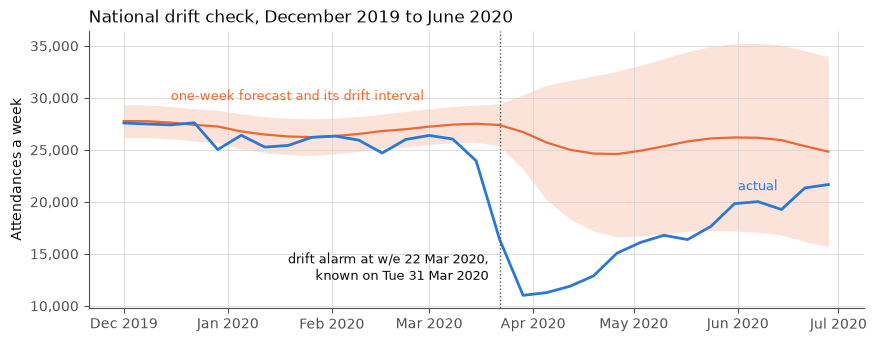

In [20]:
span = np.flatnonzero((weeks >= "2019-12-01") & (weeks <= "2020-06-28"))
point = nat["issued"][span - 1, 0]
half = nat["hw"][span]
actual = run.series["Scotland"][span]
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.fill_between(
    weeks[span], point - half, point + half, color=ORANGE, alpha=0.18, lw=0
)
ax.plot(weeks[span], point, color=ORANGE, lw=1.6)
ax.plot(weeks[span], actual, color=BLUE, lw=2)
alarm = pd.Timestamp("2020-03-22")
ax.axvline(alarm, color=MUTED, lw=1, ls=":")
ax.annotate(
    "drift alarm at w/e 22 Mar 2020,\nknown on Tue 31 Mar 2020",
    (alarm, 12500),
    xytext=(-8, 0),
    textcoords="offset points",
    ha="right",
    color=INK,
    fontsize=9,
)
ax.text(
    weeks[span][2],
    point[2] + half[2] + 600,
    "one-week forecast and its drift interval",
    color=ORANGE,
    fontsize=9,
)
late = int(np.flatnonzero(weeks[span] == pd.Timestamp("2020-06-07"))[0])
ax.text(
    weeks[span][late],
    actual[late] + 1100,
    "actual",
    color=BLUE,
    ha="center",
    fontsize=9,
)
ax.set_title(
    "National drift check, December 2019 to June 2020", loc="left", color=INK
)
ax.set_ylabel("Attendances a week")
ax.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%b %Y"))
fig.savefig(FIGURES / "drift_march_2020.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:
g3 = ev.g3(run)
print(
    f"National drift alarm: w/e {g3['first_alarm_2020']}, known {g3['known']}"
)
display(pd.DataFrame(g3["national_episodes"]))
primaries = ev.primaries(run, NAMES)
print(
    f"{primaries['total_switches']} switches of primary across "
    f"{primaries['series_switched']} series; to each model: "
    f"{primaries['switches_by_target']}; primary at the end of the data: "
    f"{primaries['final']}"
)

National drift alarm: w/e 2020-03-22, known 2020-03-31


,first_breach,alarm,last_alarm,reset,first_direction,chosen_at_reset
0,2020-03-15,2020-03-22,2020-05-17,2020-07-12,down,4-week moving average
1,2023-01-08,2023-01-15,2023-01-15,2023-03-12,down,SA-MA
2,2025-12-21,2025-12-28,2026-01-18,2026-03-15,down,linear


55 switches of primary across 31 series; to each model: {'4-week moving average': 23, 'SA-MA': 19, 'linear': 8, 'seasonal naive': 5}; primary at the end of the data: {'4-week moving average': 11, 'SA-MA': 9, 'linear': 8, 'seasonal naive': 3}


In [22]:
replay = ev.replay_set(frame, run.weeks)
full = {o: tl.screen_at(run, o) for o in replay["by_origin"]}
print(
    "The full screen, all 30 hospitals and the national series, would send: "
    + ", ".join(f"{len(v)} at w/e {o}" for o, v in full.items())
)
screen = [e for v in full.values() for e in v if e.hospital in REPLAY]
briefs = pd.DataFrame(
    [
        {
            "origin": f"{e.as_of:%d %b %Y}",
            "released": f"{e.release_date:%a %d %b %Y}",
            "hospital": e.name,
            "brief": e.kind,
            "demand level": e.level,
            "level from": e.level_source,
            "latched since": e.latched_since,
            "breach": e.breach_direction,
        }
        for e in screen
    ]
)
demand = sum(e.kind == "demand" for e in screen)
print(
    f"Pre-run check: {replay['total']} briefs, {replay['by_source']}; "
    f"the sixth "
    f"origin by its rule is w/e {replay['sixth_origin']}; at least one brief "
    f"comes from a flag: {demand >= 1}"
)
quiet = [o for o, v in replay["by_origin"].items() if not v["briefs"]]
print("Origins with no brief:", ", ".join(quiet))
briefs

The full screen, all 30 hospitals and the national series, would send: 2 at w/e 2019-10-06, 4 at w/e 2019-12-08, 1 at w/e 2020-03-15, 12 at w/e 2020-03-22, 4 at w/e 2021-06-13, 6 at w/e 2023-04-09
Pre-run check: 7 briefs, {'latch': 4, 'demand': 2, 'surge': 1}; the sixth origin by its rule is w/e 2023-04-09; at least one brief comes from a flag: True
Origins with no brief: 2019-12-08, 2020-03-15


,origin,released,hospital,brief,demand level,level from,latched since,breach
0,06 Oct 2019,Tue 15 Oct 2019,Royal Infirmary of Edinburgh at Little France,surge,2,surge,2019-09-29,upward
1,22 Mar 2020,Tue 31 Mar 2020,Queen Elizabeth University Hospital,latch,1,held,2020-03-22,downward
2,22 Mar 2020,Tue 31 Mar 2020,Royal Infirmary of Edinburgh at Little France,latch,1,held,2020-03-22,downward
3,22 Mar 2020,Tue 31 Mar 2020,Ninewells Hospital,latch,1,held,2020-03-22,downward
4,22 Mar 2020,Tue 31 Mar 2020,Scotland,latch,1,held,2020-03-22,downward
5,13 Jun 2021,Tue 22 Jun 2021,Ninewells Hospital,demand,2,flag,None,NaN
6,09 Apr 2023,Tue 18 Apr 2023,Lorn & Islands Hospital,demand,2,flag,None,NaN


In [23]:
records = []
for e in screen:
    rec = tl.get_track_record(
        run, tl.TrackRecordRequest(hospital=e.hospital, as_of=e.as_of)
    )
    records.append(
        {
            "origin": f"{e.as_of:%d %b %Y}",
            "hospital": e.name,
            "past outlook flags": rec.flags,
            "borne out": rec.borne_out,
            "unflagged outlooks": rec.unflagged,
            "unflagged that turned busy, %": (
                None
                if rec.unflagged_busy_pct is None
                else round(rec.unflagged_busy_pct, 1)
            ),
        }
    )
print(
    "The track record each brief would quote, from outlooks whose weeks "
    "were all released by its origin"
)
pd.DataFrame(records)

The track record each brief would quote, from outlooks whose weeks were all released by its origin


,origin,hospital,past outlook flags,borne out,unflagged outlooks,"unflagged that turned busy, %"
0,06 Oct 2019,Royal Infirmary of Edinburgh at Little France,4,4,58,34.5
1,22 Mar 2020,Queen Elizabeth University Hospital,15,10,71,14.1
2,22 Mar 2020,Royal Infirmary of Edinburgh at Little France,5,4,73,37.0
3,22 Mar 2020,Ninewells Hospital,0,0,86,30.2
4,22 Mar 2020,Scotland,9,5,77,15.6
5,13 Jun 2021,Ninewells Hospital,0,0,136,21.3
6,09 Apr 2023,Lorn & Islands Hospital,21,13,208,23.6


In [24]:
sensitivity = ev.sensitivity(wide)
print(
    "Share of hospital outlooks at each demand level, with the simulated "
    "capacity at three percentiles"
)
sensitivity.round(1)

Share of hospital outlooks at each demand level, with the simulated capacity at three percentiles


,capacity_percentile,scope,outlooks,level_1_pct,level_2_pct,level_3_pct,level_4_pct,flag_rate_unlatched_pct
0,80,all years,12990,81.8,17.8,0.1,0.2,18.2
1,80,steady years,8310,77.4,22.1,0.2,0.3,22.2
2,90,all years,12990,91.6,8.2,0.1,0.1,8.3
3,90,steady years,8310,90.0,9.7,0.1,0.2,9.6
4,95,all years,12990,95.4,4.5,0.0,0.1,4.4
5,95,steady years,8310,94.9,5.0,0.1,0.1,4.8


## 5. Agents: Investigator and Reviewer

The screen is code: it sends a hospital to the agents when it is flagged, or latched, which covers a surge or held level of 2 or more,
and nothing else reaches them. The Investigator drafts the
demand brief through five read-only typed tools, each as of the origin, following the tool-use
pattern of ReAct, reasoning interleaved with tool calls (Yao et al., 2023). It never sets the level:
its draft has no field for one, so code copies the rule's level into every brief (G5, enforced by
schema).

**What the code proves about each figure.** Code writes every figure, and what that
figure is. The Investigator cites each figure with the tool call that returned it and its measure,
such as a forecast, a range end, an actual or a back-test error, with its model, release horizon
and week. Its text holds only a placeholder for each, such as `{F1}`, and code writes the value in
with its label: "1,120 attendances (SA-MA forecast for w/e 27 Jun 2021)". Within one brief every
forecast comes from one origin, so its week names its release horizon; a back-test error keeps its
release horizon. The words around the placeholders name no number, model, release horizon, week,
hospital or level; tokens that code writes name those, such as `{PRIMARY}`, `{WEEK1}`, `{HOSPITAL}`
and `{LEVEL}`, and no week token may repeat the week a figure's label already names. Pydantic
validators refuse a draft that breaks these rules, naming every problem at once. The facts every
brief states, its primary model's own back-test error, its track record and the bank holidays
ahead, are code's: it calls the tools itself and writes each as a fixed line, so the Investigator
writes only the explanation. The Reviewer's code check then proves three things before any language
model reads the brief:

- each cited figure is what its tool call returned: its value within rounding, and its measure,
  model, release horizon, week and unit, for the same hospital and origin;
- a demand brief states the primary model's forecast, a cited figure from its tool. A surge or latch
  brief's forecasts are untrusted, so it is never asked for one, and code labels any forecast it
  cites untrusted;
- the level is the rule's.

So each number the manager reads is a tool's value, written beside its true label or in a fixed line
code writes. The code does not prove what a sentence says about a figure, such as calling an actual a
forecast. The Reviewer judges that, and so can the duty manager, who sees every label.

Only then does a language model check the wording, after a code screen for the words the MHRA lists
as indicative of a device. A failure gets one retry, with every problem named. A brief that fails
again reaches the manager marked "not verified, do not act", each problem marked where it stands,
and can never be approved (G4). A failed model call is recorded and replayed like any reply. A
Reviewer whose call fails is asked once more, and if it still gives no verdict the brief ends "not
verified", counted apart by that cause.

I adapted the model gateway with its recordings and exact replay, the typed tools, the approval
queue and the audit log from Agentic AI Systems. The model backend is one value in `config.json`,
`llm_backend`. It ships as `frontier`, the Claude API, because the frontier set is the one approved;
a live frontier run needs a stated case from the adequacy test, with its key read from the
git-ignored `.env` alone. Setting it to `local` selects Ollama on this machine, with the model
pinned by digest. The replay below reads the recordings on either setting.

**No language model runs in this notebook.** Every model reply in sections 5 to 7 is read from the
live run's recordings in `recordings/`; a missing or changed recording stops the notebook.

In [25]:
settings = cf.load_config("config.json")
HOLIDAYS = "bank-holidays_20261024.json"
holidays = dt.load_bank_holidays(DATA / HOLIDAYS, manifest[HOLIDAYS].sha256)
config_text = Path("config.json").read_text(encoding="utf-8")
local, frontier = settings.local, settings.frontier
# The replay below reads each set's backend from its recordings, so this
# setting matters only to a live run.
print("Model backend in config.json:", settings.llm_backend)
print(
    f"Local, if chosen: {local.model}, pinned by digest {local.digest[:12]}, "
    f"temperature {local.temperature:g}, reasoning effort "
    f"{local.reasoning_effort}, at {local.endpoint}"
)
temperature = (
    "the API's default temperature"
    if frontier.temperature is None
    else f"temperature {frontier.temperature:g}"
)
print(
    f"Frontier, run live only with a stated case: {frontier.model}, at "
    f"{temperature}; it cannot be pinned by digest. Its key is read from the "
    "git-ignored .env alone, and config.json names its variable, "
    f"{frontier.api_key_env}, and holds no secret: "
    f"{not cf.secret_like(config_text)}"
)
print("What the agent writes:", ", ".join(br.BriefDraft.model_fields))
print(
    "What code sets:",
    ", ".join(
        f
        for f in br.DemandBrief.model_fields
        if f not in br.BriefDraft.model_fields
    ),
)
attempt = {f: "Some text." for f in br.TEXT_FIELDS if f != "watch_points"}
attempt.update(watch_points=["Check cover."], cited_figures=[], level=3)
try:
    br.BriefDraft.model_validate(attempt)
except ValidationError as exc:
    error = exc.errors()[0]
    print(
        f"A draft that sets its own level is refused: {error['type']} on "
        f"{error['loc'][0]!r}"
    )
del attempt["level"]
attempt["summary"] = "Expect 1,120 attendances."
try:
    br.BriefDraft.model_validate(attempt)
except ValidationError as exc:
    print(
        "A draft that writes a figure itself is refused:",
        br.problems_of(exc)[0],
    )

Model backend in config.json: frontier
Local, if chosen: nemotron-3.5-lightning:30b-a3b, pinned by digest e7a64ff15fb1, temperature 0, reasoning effort medium, at http://localhost:11434/v1
Frontier, run live only with a stated case: claude-sonnet-5-5, at the API's default temperature; it cannot be pinned by digest. Its key is read from the git-ignored .env alone, and config.json names its variable, ANTHROPIC_API_KEY, and holds no secret: True
What the agent writes: summary, expected_range, model_agreement, watch_points, cited_figures
What code sets: brief_id, hospital, name, week, release_date, kind, level, level_source, level_meaning, drift_alarm, latched_since, breach_direction, backtest_error, track_record, bank_holidays, primary, backend, model, model_digest
A draft that sets its own level is refused: extra_forbidden on 'level'
A draft that writes a figure itself is refused: summary: 1,120: write each figure as its placeholder, such as {F1}; code writes the number and what it is


**The safeguards shown acting, with a scripted stand-in.** Before the live run, a scripted stand-in
plays the model's part for Ninewells Hospital at w/e 13 Jun 2021, so the safeguards can be seen
acting with no model and no GPU. Nothing it says is a model's output: its drafts cite only true tool
values, written as placeholders that code fills in with their labels, and the planted ones add a
figure or a date no tool returned. It goes through the same graph, queue and coordinator as the live
run, and writes nothing in the repository.

In [26]:
shown = dm.safeguards(run, holidays, settings)
print(shown.label)
first = shown.caught.attempts[0]
print(
    "1. A figure planted by code in the first readable draft, as the designed "
    f"failure plants it. Caught at that figure by the code check: "
    f"{shown.caught.planted_caught}"
)
for failure in first.check.failures:
    print(f"   {failure.field}: {failure.reason}")
print(
    f"   After the one retry: {shown.caught.status}, in "
    f"{len(shown.caught.attempts)} attempts"
)
print(f"2. A brief planted twice: {shown.refused.status}.")
print(f"   An approval is refused: {shown.refusal}")
print("3. A manager's edit that fails the code check comes back marked:")
for line in shown.failed_edit.splitlines():
    if "NOT VERIFIED" in line:
        print(f"   {line}")
note = shown.notified.drafts[0]
print(
    f"4. A drafted notification with a planted date, {shown.planted_date}. "
    f"Caught before the outbox: {not note.check.passed}"
)
for failure in note.check.failures:
    print(f"   {failure.reason}")
print(shown.notified.summary())

Scripted stand-in: nothing it says is a model's output.
1. A figure planted by code in the first readable draft, as the designed failure plants it. Caught at that figure by the code check: True
   cited_figures[4]: 1535 is not SA-MA's forecast at release horizon 1 in T1
   After the one retry: verified, in 2 attempts
2. A brief planted twice: not verified.
   An approval is refused: demo-refused is not verified, do not act: it can never be approved
3. A manager's edit that fails the code check comes back marked:
   NOT VERIFIED, DO NOT ACT: it can never be approved.
   Summary: The forecasts put demand above the usual, starting at 1,120 attendances (SA-MA forecast for w/e 27 Jun 2021). Expect [[NOT VERIFIED: 1,450 attendances (SA-MA forecast for w/e 27 Jun 2021)]].
4. A drafted notification with a planted date, 25 Jun 2021. Caught before the outbox: True
   10: write each figure as its placeholder, such as {F1}; code writes the number and what it is
   00: write each figure as its plac

### The live runs, replayed

No language model runs in this notebook. An AI assistant session, on my instruction, ran each set
live from the repository root, and the cells below replay the recordings in `recordings/`; a missing or changed recording
stops the notebook.

The adequacy test, stated before any brief existed, decided which sets ran. The seven replay briefs and
the designed failure run first on the local backend. A brief is adequate when it is verified and
meets at least 5 of the 6 approval criteria, as an AI reviewer, on my instruction, scores it, and a set
needs 6 of its 7. A first local round short of that gets one bounded prompt-tuning round, then a
second round under a new label. A second local round short of that is the stated case for one run
on the frontier backend, on the same replay set and the same prompts.

Three sets are recorded:

- `round1` on the local backend: `python -m ae_escalation.live briefs --label round1`, within the
  840-second budget in `config.json`;
- `round2` on the local backend, after the tuning round: the same command with `--label round2
  --budget-s 1800`;
- `round2` on the frontier backend, its one run: the same command, with `llm_backend` set to
  `frontier`.

Each local run checks the model's digest first. Then `live adequacy --label <label>` records each
adequacy test in `approvals/`, and `live choose` records the approver's choice of set. Once the
approver's decisions are saved, `live notify` has the Reviewer check each edit and the coordinator
draft the notifications, written to `outbox/` and never sent. Every model call, failed calls
included, is recorded beside its label, with the prompts that label ran with.

In [27]:
# Every live run recorded, by label and backend, and the set that goes to
# approval: the approver's chosen set, else the local set whose record sends
# it to approval, else the last label.
labels = sorted(
    {p.parent.name for p in Path("recordings").glob("*/*/briefs.jsonl")}
)
labels = labels or ["round1"]
sets = {
    (label, backend): rp.Paths.under(Path("."), backend, label)
    for label in labels
    for backend in ("local", "frontier")
    if rp.Paths.under(Path("."), backend, label).briefs.exists()
}
choices = sorted(Path("approvals").glob("set_choice_*.md"))
sent = [
    label
    for label in labels
    if rp.Paths.under(Path("."), "local", label).adequacy_record.exists()
    and "Goes to approval: yes"
    in rp.Paths.under(Path("."), "local", label).adequacy_record.read_text(
        encoding="utf-8"
    )
]
if choices:
    choice = choices[-1]
    LABEL = choice.stem.removeprefix("set_choice_")
    text = choice.read_text(encoding="utf-8")
    chosen = "frontier" if "the frontier set" in text else "local"
else:
    LABEL = sent[-1] if sent else labels[-1]
    choice = Path("approvals") / f"set_choice_{LABEL}.md"
    chosen = "local"
paths = rp.Paths.under(Path("."), chosen, LABEL)
chosen_settings = settings.model_copy(update={"llm_backend": chosen})
recorded = ", ".join(f"{label} ({backend})" for label, backend in sets)
print(
    f"Sets recorded: {recorded or 'none yet'}; the set that goes to "
    f"approval: {LABEL}, {chosen}"
)

Sets recorded: round1 (local), round2 (local), round2 (frontier); the set that goes to approval: round2, frontier


In [28]:
# Every recorded set is replayed and reported, each label and each backend,
# so the first round's evidence stays in view after the tuning round; the
# chosen set goes on to approval. A set stopped
# at its budget has only the runs it completed recorded whole, so those alone
# replay, and its stop is shown as the adequacy record states it.
replayed, stops = {}, {}
for (label, backend), p in (sets or {(LABEL, chosen): paths}).items():
    replayed[(label, backend)], stops[(label, backend)] = rp.replay_label(
        run,
        holidays,
        settings.model_copy(update={"llm_backend": backend}),
        p,
    )
result = replayed[(LABEL, chosen)]
print(f"Pre-run check: {result.check}")
for (label, backend), stop in stops.items():
    if stop is not None:
        print(f"The {backend} set, {label}. {stop.line()}")
pd.DataFrame(
    [
        {
            "label": label,
            "set": backend,
            "brief": o.run_id,
            "hospital": NAMES[o.hospital],
            "origin": f"{o.origin:%Y-%m-%d}",
            "kind": o.entry.kind,
            "demand level": o.entry.level,
            "status": o.status,
            "not verified because": o.cause or "",
            "each attempt refused by": "; ".join(
                f"{a.number}: {a.refused_by or 'passed'}" for a in o.attempts
            ),
            "model": o.model,
            "model calls": len(o.calls),
            "failed calls": sum(bool(c.error) for c in o.calls),
            "all replayed": all(c.replayed for c in o.calls),
        }
        for (label, backend), r in replayed.items()
        for o in r.outcomes
    ]
)

Pre-run check: {'total': 7, 'by_source': {'latch': 4, 'demand': 2, 'surge': 1}, 'flag_briefs': 2, 'sixth_origin': '2023-04-09', 'matches_probe': True}
The local set, round1. Stopped at its budget: the live run reached its budget of 840 s during model call 4 of run 20200322-T101H. Completed: 20191006-S314H, 20200322-Scotland, 20200322-S314H. Unfinished: 20200322-T101H (in progress), 20200322-G405H, 20210613-T101H, 20230409-C121H, and the designed failure, 20210613-T101H-planted. Each unfinished brief is counted not adequate.


,label,set,brief,hospital,origin,kind,demand level,status,not verified because,each attempt refused by,model,model calls,failed calls,all replayed
0,round1,local,20191006-S314H,Royal Infirmary of Edinburgh at Little France,2019-10-06,surge,2,not verified,the code check,1: the code check; 2: the code check,nemotron-3.5-lightning:30b-a3b,7,2,True
1,round1,local,20200322-Scotland,Scotland,2020-03-22,latch,1,not verified,the code check,1: the code check; 2: the code check,nemotron-3.5-lightning:30b-a3b,8,2,True
2,round1,local,20200322-S314H,Royal Infirmary of Edinburgh at Little France,2020-03-22,latch,1,not verified,the code check,1: the code check; 2: the code check,nemotron-3.5-lightning:30b-a3b,8,2,True
3,round2,local,20191006-S314H,Royal Infirmary of Edinburgh at Little France,2019-10-06,surge,2,not verified,the draft reply was cut at the output cap,1: the draft reply was cut at the output cap; 2: the draft reply was cut at the output cap,nemotron-3.5-lightning:30b-a3b,7,2,True
4,round2,local,20200322-Scotland,Scotland,2020-03-22,latch,1,not verified,the draft reply was cut at the output cap,1: the draft reply was cut at the output cap; 2: the draft reply was cut at the output cap,nemotron-3.5-lightning:30b-a3b,7,2,True
5,round2,local,20200322-S314H,Royal Infirmary of Edinburgh at Little France,2020-03-22,latch,1,not verified,the draft reply was cut at the output cap,1: the draft reply was cut at the output cap; 2: the draft reply was cut at the output cap,nemotron-3.5-lightning:30b-a3b,7,2,True
6,round2,local,20200322-T101H,Ninewells Hospital,2020-03-22,latch,1,not verified,the draft reply was cut at the output cap,1: the draft reply was cut at the output cap; 2: the draft reply was cut at the output cap,nemotron-3.5-lightning:30b-a3b,8,2,True
7,round2,local,20200322-G405H,Queen Elizabeth University Hospital,2020-03-22,latch,1,not verified,the draft reply was cut at the output cap,1: the draft reply was cut at the output cap; 2: the draft reply was cut at the output cap,nemotron-3.5-lightning:30b-a3b,7,2,True
8,round2,local,20210613-T101H,Ninewells Hospital,2021-06-13,demand,2,not verified,the draft reply was cut at the output cap,1: the draft reply was cut at the output cap; 2: the draft reply was cut at the output cap,nemotron-3.5-lightning:30b-a3b,7,2,True
9,round2,local,20230409-C121H,Lorn & Islands Hospital,2023-04-09,demand,2,not verified,the draft reply was cut at the output cap,1: the draft reply was cut at the output cap; 2: the draft reply was cut at the output cap,nemotron-3.5-lightning:30b-a3b,8,2,True


In [29]:
for (label, backend), r in replayed.items():
    print(f"The {backend} set, {label}, each brief as the manager sees it")
    if stops[(label, backend)] is not None:
        print(
            f"The {len(r.outcomes)} briefs the run completed before its "
            "budget stopped it"
        )
    print()
    for o in r.outcomes:
        print(o.display())
        print()

The local set, round1, each brief as the manager sees it
The 3 briefs the run completed before its budget stopped it

NOT VERIFIED, DO NOT ACT: it can never be approved.
No readable brief: model error: ValidationError: 1 validation error for BriefDraft
  Value error, model_agreement: 1: write each figure as its placeholder, such as {F1}; code writes the number and what it is
model_agreement: 2: write each figure as its placeholder, such as {F1}; code writes the number and what it is
model_agreement: 3: write each figure as its placeholder, such as {F1}; code writes the number and what it is
model_agreement: 4: write each figure as its placeholder, such as {F1}; code writes the number and what it is [type=value_error, input_value={'summary': 'Forecasts in...k': None, 'unit': '%'}]}, input_type=dict]
    For further information visit https://errors.pydantic.dev/2.14/v/value_error

NOT VERIFIED, DO NOT ACT: it can never be approved.
No readable brief: model error: ValidationError: 1 valid

In [30]:
for (label, backend), r in replayed.items():
    planted = r.planted
    if planted is None:
        print(
            f"The designed failure, {backend} set, {label}: not finished, "
            "since the run stopped at its budget first, so the planted "
            "figure was never shown caught"
        )
        continue
    if planted.planted_attempt is None:
        print(
            f"The designed failure, {backend} set, {label}, "
            f"{planted.run_id}: no readable draft came, so code never "
            "planted the figure and the check was never shown catching it. "
            f"The run ended {planted.status}; its cause: {planted.cause}"
        )
        continue
    print(
        f"The designed failure, {backend} set, {label}, {planted.run_id}: a "
        "figure planted by code in the Investigator's first readable draft, "
        f"in attempt {planted.planted_attempt}. Caught at the planted figure "
        f"by the code check: {planted.planted_caught}"
    )
    attempt = next((a for a in planted.attempts if a.planted), None)
    for failure in attempt.check.failures if attempt and attempt.check else []:
        print(f"   {failure.field}: {failure.reason}")
    print(f"After the one retry: {planted.status}")

The designed failure, local set, round1: not finished, since the run stopped at its budget first, so the planted figure was never shown caught
The designed failure, local set, round2, 20210613-T101H-planted: no readable draft came, so code never planted the figure and the check was never shown catching it. The run ended not verified; its cause: the draft reply was cut at the output cap
The designed failure, frontier set, round2, 20210613-T101H-planted: a figure planted by code in the Investigator's first readable draft, in attempt 1. Caught at the planted figure by the code check: True
   expected_range: first: write each figure as its placeholder, such as {F1}; code writes the number and what it is
   expected_range: 80: write each figure as its placeholder, such as {F1}; code writes the number and what it is
   expected_range: %: each figure's label writes its own unit; write no % in the words
   expected_range: 95: write each figure as its placeholder, such as {F1}; code writes the 

In [31]:
for (label, backend), r in replayed.items():
    total = r.check["total"]
    verified = sum(o.status == "verified" for o in r.outcomes)
    causes = [o.cause for o in r.outcomes if o.status == "not verified"]
    by_cause = {c: causes.count(c) for c in sorted(set(causes))}
    g5 = ap.g5_verdict(r.outcomes)
    blind = rp.blind_retries(rp.Paths.under(Path("."), backend, label))
    scope = (
        f", stopped at its budget after {len(r.outcomes)} of the {total} "
        "briefs"
        if stops[(label, backend)] is not None
        else ""
    )
    print(
        f"The {backend} set, {label}{scope}: {verified} of {total} verified."
    )
    print(
        f"   G4 events, briefs marked not verified: {len(causes)}, by cause "
        f"{by_cause}"
    )
    if g5["briefs"]:
        print(
            "   G5, the level in every brief written equals the rule's: "
            f"{g5['level_is_rules']} of {g5['briefs']}"
        )
    else:
        print(
            "   G5: no brief was written, so none to hold to the rule's level"
        )
    print(
        "   Retries that went out blind, the first attempt's request sent "
        f"again: {sum(blind.values())} of {len(blind)}"
    )

The local set, round1, stopped at its budget after 3 of the 7 briefs: 0 of 7 verified.
   G4 events, briefs marked not verified: 3, by cause {'the code check': 3}
   G5: no brief was written, so none to hold to the rule's level
   Retries that went out blind, the first attempt's request sent again: 3 of 3
The local set, round2: 0 of 7 verified.
   G4 events, briefs marked not verified: 7, by cause {'the draft reply was cut at the output cap': 7}
   G5: no brief was written, so none to hold to the rule's level
   Retries that went out blind, the first attempt's request sent again: 0 of 8
The frontier set, round2: 5 of 7 verified.
   G4 events, briefs marked not verified: 2, by cause {'the wording check': 2}
   G5, the level in every brief written equals the rule's: 7 of 7
   Retries that went out blind, the first attempt's request sent again: 0 of 7


In [32]:
# Each set's model calls, tokens and model time, read from its recordings,
# the designed failure included: what the backend tradeoff rests on. A
# failed call's record holds no token counts, so tokens cover the calls that
# answered, while model time covers every call.
rows = []
for (label, backend), r in replayed.items():
    runs = [*r.outcomes, *([r.planted] if r.planted else [])]
    calls = [c for o in runs for c in o.calls]
    rows.append(
        {
            "label": label,
            "set": backend,
            "model": r.model,
            "tool-loop calls": sum(c.purpose == "tool loop" for c in calls),
            "draft calls": sum(c.purpose == "draft" for c in calls),
            "wording checks": sum(c.purpose == "wording" for c in calls),
            "failed calls": sum(bool(c.error) for c in calls),
            "tokens in, answered calls": sum(c.tokens_in for c in calls),
            "tokens out, answered calls": sum(c.tokens_out for c in calls),
            "model time, s": round(sum(c.latency_s for c in calls), 1),
        }
    )
    if stops[(label, backend)] is not None:
        print(
            f"The {backend} set, {label}, counts only the {len(runs)} runs it "
            "completed before its budget stopped it."
        )
pd.DataFrame(rows).set_index(["label", "set"])

The local set, round1, counts only the 3 runs it completed before its budget stopped it.


model  tool-loop calls  draft calls  wording checks  failed calls  \
label  set                                                                                                    
round1 local     nemotron-3.5-lightning:30b-a3b               17            6               0             6   
round2 local     nemotron-3.5-lightning:30b-a3b               42           16               0            16   
       frontier               claude-sonnet-5-5               30           15               8             0   

                 tokens in, answered calls  tokens out, answered calls  model time, s  
label  set                                                                             
round1 local                         78434                      135708          802.6  
round2 local                        194704                       82308          656.9  
       frontier                     326687                       18252          169.8

**Round 1's record and the replay name its cause differently.** Round 1's client checked each
typed reply against the brief's schema inside the model call, so a draft the text rules refused
was recorded as a model error. The record written then says the Investigator could not run.
The replay reads the recorded error and names the code check, which refused both drafts in each
of the three briefs round 1 completed. Each of its retries went out blind, sending the first
attempt's request again, so the retry never saw its problems. In round 2 the client read each
reply in code, after the call, and no retry on either backend went out blind.

In [33]:
for label, backend in replayed:
    record = rp.Paths.under(Path("."), backend, label).adequacy_record
    if record.exists():
        print(record.read_text(encoding="utf-8"))
if choice.exists():
    print(choice.read_text(encoding="utf-8"))

# Adequacy test record: local backend, nemotron-3.5-lightning:30b-a3b, round1 (round 1)

0 of 7 adequate: one bounded prompt-tuning round, then score the set again. The briefs, not the stop, decided this verdict: had every unfinished brief been adequate, the set would have had 4 of 7, short of the 6 the verdict needs.

Stopped at its budget: the live run reached its budget of 840 s during model call 4 of run 20200322-T101H. Completed: 20191006-S314H, 20200322-Scotland, 20200322-S314H. Unfinished: 20200322-T101H (in progress), 20200322-G405H, 20210613-T101H, 20230409-C121H, and the designed failure, 20210613-T101H-planted. Each unfinished brief is counted not adequate.

Round: 1
Frontier case: no
Goes to approval: no
Prompt-tuning round next: yes
Run budget: not in the progress file, which this label wrote before the budget was recorded there.
Decided by the stop: no

| Brief | Status | Criteria met | Not met | Adequate |
|---|---|---|---|---|
| 20191006-S314H | not verified: the Invest

**What the replays show.**

- **Local round 1** completed 3 of its 7 briefs before its 840-second budget stopped it, and
  verified none. The code check refused both drafts of each, and each retry went out blind, a bug
  in my client that round 2 fixed. The designed failure never ran.
- **Local round 2** completed every run and verified none. Every draft reply was cut at the output
  cap of 8,192 tokens, so no draft could be read and no figure could be planted. The cap counts
  the model's thinking, and a retry with thinking turned off is untried (section 9).
- **The frontier set** verified 5 of 7: the surge brief and the four latch briefs, four of them on
  the retry. Both demand briefs failed the code check first, then the wording check, where the
  Reviewer found claims no tool result supports, such as that the forecasts fit recent weeks, so
  neither could be approved; the fix is future work before shadow mode. The code check caught the
  planted figure, 1535, in the designed failure's first draft.
- **G5 holds** in every brief written: 7 of 7 in the frontier set. The local sets wrote none.
- **The adequacy records** give no local brief adequate in either round, round 1 counting its four
  unfinished briefs as not adequate, and 5 of 7 on the frontier backend, so neither backend reached
  6 of 7, for the causes above. Both sets are reported, and the approver chose the frontier set
  for approval, which is why `config.json` ships set to `frontier`.

**The backend tradeoff, in figures.** The frontier set took 30 tool-loop calls, 15 draft calls and 8
wording checks: 326,687 tokens in and 18,252 out, and 169.8 seconds of model time. Local round 2
took 656.9 seconds of model time and wrote no readable draft, each cut at the output cap. The local model runs on this machine, costs nothing
per call and is pinned by digest. The frontier model costs money for each token, depends on an
outside service and cannot be pinned the same way. I did not try the local model with its thinking
turned off (section 9).

## 6. Approval and coordination

Each verified brief goes to the approval queue. The approver approves, edits or rejects it with
initials and a timestamp, and records which of the six approval criteria it met; the criteria were
written before any brief existed. Only a verified brief can be approved. Every edit re-runs the
code figure check, the device-word screen and the Reviewer's wording check, and an edit that fails
comes back marked "not verified, do not act", never to the Investigator. Code marks an edit factual
when it changes a cited figure, or a figure, date, level or hospital in the text, and the approver
may also declare one.

In the spot check one person plays three roles: the approver; the unscheduled-care lead, who owns
the thresholds and approves each latch reset; and the analytics lead, who re-selects the primary
model at each reset. The clinical safety reviewer's sign-off is not exercised, because there is no
live use.

The coordinator is code. It sets the staffing actions for the level, assigns each to a role, sets
its reply deadline, tracks it and escalates it when the deadline passes. The actions are
illustrative, on the structure of OPEL Appendix F only: actions by level with an owner each. The
language model drafts only each notification's wording, under the same token rules as a brief:
every figure is a placeholder that code writes with its label, and code writes the hospital,
level, weeks and deadline. Before the outbox, Pydantic allows only figures the approved brief
states, none of them a past week's actual, each for the action's weeks or for no one week. The clock
runs in UK time, Europe/London. Notifications go to an outbox file and are never sent, and the
acknowledgements are simulated.

In [34]:
pd.DataFrame(
    [{"criterion": c.name, "met when": c.test} for c in ap.CRITERIA],
    index=pd.RangeIndex(1, 7, name="#"),
)

,criterion,met when
#,,
1,Figures correct,Every figure matches its tool result.
2,Uncertainty stated,"The range, the hospital's own back-test error and its track record are given."
3,Model disagreement named,"Where the forecasts disagree, the brief says so, and says which to trust less and why."
4,The level's meaning stated,"Demand for the time of year, not pressure, need or priority."
5,Watch points actionable,Each names something a manager can check or do this week.
6,No clinical instruction,Nothing reads as an instruction to a clinician.


In [35]:
hours = settings.coordinator.reply_deadline_hours
actions = pd.DataFrame(
    [
        {
            "level": level,
            "action": a.code,
            "task": a.task,
            "owner": a.owner,
            "escalated to": co.ESCALATE_TO[a.owner] or "no role above",
            "reply within, hours (assumed)": hours[level],
        }
        for level in (2, 3, 4)
        for a in co.actions_for(level)
    ]
).set_index(["level", "action"])
print(
    "Level 1 sets no staffing action. The actions are illustrative, and the "
    "deadlines and the replay clock's 10:00 start, UK time, on release day "
    "are assumed."
)
actions

Level 1 sets no staffing action. The actions are illustrative, and the deadlines and the replay clock's 10:00 start, UK time, on release day are assumed.


task  \
level action                                                                                                                                          
2     check-cover                                                          Check whether extra shifts or bank staff are needed for the weeks ahead.   
      hold-leave                                                Hold new leave requests for the weeks ahead until the duty manager's check is done.   
3     check-cover                                                          Check whether extra shifts or bank staff are needed for the weeks ahead.   
      hold-leave                                                Hold new leave requests for the weeks ahead until the duty manager's check is done.   
      request-bank                                                                                Ask the staff bank for cover for the weeks ahead.   
4     check-cover                                                          Check whether extra shifts or bank staff are needed for the weeks ahead.   
      hold-leave                                                Hold new leave requests for the weeks ahead until the duty manager's check is done.   
      request-bank                                                                                Ask the staff bank for cover for the weeks ahead.   
      inform-lead   Tell the unscheduled-care lead, who decides on any further front-door cover, about the shifts and bank staff already requested.   

                                    owner           escalated to  reply within, hours (assumed)  
level action                                                                                     
2     check-cover            duty manager  unscheduled-care lead                             48  
      hold-leave         rota coordinator           duty manager                             48  
3     check-cover            duty manager  unscheduled-care lead                             24  
      hold-leave         rota coordinator           duty manager                             24  
      request-bank      staff bank office           duty manager                             24  
4     check-cover            duty manager  unscheduled-care lead                             12  
      hold-leave         rota coordinator           duty manager                             12  
      request-bank      staff bank office           duty manager                             12  
      inform-lead   unscheduled-care lead          no role above                             12

In [36]:
queue = rp.queue_with_decisions(result, paths, settings=chosen_settings)
for refusal in queue.refusals:
    print(f"Refused, and logged: {refusal['reason']}")
criterion = {c.field: c.name for c in ap.CRITERIA}
pd.DataFrame(
    [
        {
            "brief": i.brief_id,
            "state": i.state,
            "decided": "; ".join(
                f"{d.action} by {d.initials} at {d.decided_at:%d %b %Y %H:%M}"
                for d in i.decisions
            ),
            "criteria not met": "; ".join(
                criterion[f]
                for d in i.decisions
                for f, ok in d.criteria
                if not ok
            )
            or "none",
            "factual edit": any(d.factual_edit for d in i.decisions),
            "edit's wording check": (
                ""
                if i.edit_wording is None
                else "passed" if i.edit_wording.passed else "failed"
            ),
        }
        for i in queue.items()
    ]
)

,brief,state,decided,criteria not met,factual edit,edit's wording check
0,20191006-S314H,approved with edit,edit by PG at 26 Oct 2026 11:50,none,False,passed
1,20200322-Scotland,approved with edit,edit by PG at 26 Oct 2026 11:50,Watch points actionable,False,passed
2,20200322-S314H,approved with edit,edit by PG at 26 Oct 2026 11:50,none,False,passed
3,20200322-T101H,approved with edit,edit by PG at 26 Oct 2026 11:50,Watch points actionable,False,passed
4,20200322-G405H,approved with edit,edit by PG at 26 Oct 2026 11:50,Watch points actionable,False,passed
5,20210613-T101H,rejected,reject by PG at 26 Oct 2026 11:50,Uncertainty stated,False,
6,20230409-C121H,rejected,reject by PG at 26 Oct 2026 11:50,Uncertainty stated; Watch points actionable,False,


In [37]:
# Each decision's note, and what each approved edit changed, field by
# field, as the manager reads it.
for i in queue.items():
    for d in i.decisions:
        print(f"{i.brief_id}, {i.state}. Note: {d.note}")
    if i.state != "approved with edit":
        print()
        continue
    was, now = i.outcome.brief.rendered(), i.current.rendered()
    for field in dict.fromkeys([*was, *now]):
        if was.get(field) != now.get(field):
            print(f"   {field}, was: {was.get(field, '(none)')}")
            print(f"   {field}, now: {now.get(field, '(none)')}")
    print()

20191006-S314H, approved with edit. Note: PG ruling A, 26 Oct 2026: approve with edit. The AI independent judge's required edits are adopted as PG's own, with the main session's correction to the reset wording: a person approves a latch reset once the documented reset criteria are met. Criteria as the judge ticked them on the brief as drafted, except Figures correct, ticked on the independent adequacy scorer's check of every figure against its tool result and the hash-checked data file (reviews/rescope/adequacy_scores_frontier_round2_20261026.md).
   model_agreement, was: All forecasts are untrusted while the drift latch is set, so no forecast is offered as guidance.
   model_agreement, now: All forecasts are untrusted while the drift latch is set, so no forecast is offered as guidance. The back-test error in this brief is historical and does not establish current forecast reliability while the latch is set.
   watch_points[2], was: Ask for the latch reset to be reviewed once the follo

In [38]:
verdict = {True: "met", False: "not met", None: "waits on Reader B"}
g4 = ap.g4_verdict(queue, result.planted)
print(
    f"G4, the {chosen} set: {g4['approved_passing_code_check']} of "
    f"{g4['approved']} approved briefs pass the code check again; "
    f"{g4['not_verified_approved']} of the {g4['not_verified']} not "
    "verified were approved; the planted figure caught at that figure: "
    f"{g4['planted_caught']}. G4 {verdict[g4['met']]}."
)
# Reader B's sheet is typed from the returned form; until it exists, G6
# waits on it unless the approver's count already fails it.
four = [
    rp.run_id(e)
    for e in rp.reader_b_four(rp.replay_entries(run), rp.sizes(run))
]
agreement = None
if paths.reader_b.exists():
    readings = ap.read_reader_b(paths.reader_b)
    agreement = ap.reader_b_agreement(queue, readings, four)
    for brief_id, b in agreement["by_brief"].items():
        print(
            f"Reader B on {brief_id}: {b['reader_b']}; the approver: "
            f"{b['approver']}; the same decision: {b['agree']}"
        )
agreeing = (
    agreement["agreeing"] if agreement and agreement["complete"] else None
)
g6 = ap.g6_verdict(
    queue, built=result.check["total"], reader_b_agreeing=agreeing
)
if agreement is None:
    reader_b = "not yet recorded"
elif agreement["complete"]:
    reader_b = f"{agreement['agreeing']} of {len(four)} agree"
else:
    reader_b = (
        f"{agreement['agreeing']} of the {agreement['read']} read so far"
    )
print(
    f"G6: {g6['approved_without_factual_edit']} of the {g6['built']} built "
    "briefs approved by the approver without a factual edit, where all but "
    f"one, {g6['needed']}, are needed. Reader B's agreement on the four, "
    f"{', '.join(four)}: {reader_b}. G6 {verdict[g6['met']]}."
)

G4, the frontier set: 5 of 5 approved briefs pass the code check again; 0 of the 2 not verified were approved; the planted figure caught at that figure: True. G4 met.
Reader B on 20191006-S314H: edit; the approver: edit; the same decision: True
Reader B on 20200322-Scotland: edit; the approver: edit; the same decision: True
Reader B on 20200322-T101H: edit; the approver: edit; the same decision: True
Reader B on 20210613-T101H: reject; the approver: reject; the same decision: True
G6: 5 of the 7 built briefs approved by the approver without a factual edit, where all but one, 6, are needed. Reader B's agreement on the four, 20210613-T101H, 20191006-S314H, 20200322-Scotland, 20200322-T101H: 4 of 4 agree. G6 not met.


In [39]:
# The replay writes to an outbox of its own, so the live run's outbox is
# never rewritten, and the two are compared after.
replayed_outbox = Path(tempfile.mkdtemp()) / paths.outbox.name
done = rp.coordinate_approved(
    queue, chosen_settings, paths, live=False, outbox=replayed_outbox
)
for d in done:
    print(d.brief_id)
    print(d.summary())
    print()
# A replay that wrote nothing leaves no file; the live run writes an empty
# one.
replayed_text = (
    replayed_outbox.read_text(encoding="utf-8")
    if replayed_outbox.exists()
    else ""
)
written = replayed_text.splitlines()
print(f"The outbox, {len(written)} entries, never sent:")
for line in written:
    n = json.loads(line)
    print(f"- {n['kind']} to the {n['to']}, {n['brief_id']}: {n['message']}")
if paths.outbox.exists():
    same = replayed_text == paths.outbox.read_text(encoding="utf-8")
    print(
        f"The replayed outbox matches the live run's, {paths.outbox}, line "
        f"for line: {same}"
    )

20191006-S314H
check-cover | duty manager | reply by 10:00 UK time on Thu 17 Oct 2019 | acknowledged
hold-leave | rota coordinator | reply by 10:00 UK time on Thu 17 Oct 2019 | acknowledged late
Written to the outbox file, never sent.
Simulated: the acknowledgements are seeded stand-ins, not real replies, and the clock is the replay's.

20200322-Scotland
Level 1 sets no staffing action, so nothing reaches the outbox.

20200322-S314H
Level 1 sets no staffing action, so nothing reaches the outbox.

20200322-T101H
Level 1 sets no staffing action, so nothing reaches the outbox.

20200322-G405H
Level 1 sets no staffing action, so nothing reaches the outbox.

The outbox, 3 entries, never sent:
- notification to the duty manager, 20191006-S314H: Royal Infirmary of Edinburgh at Little France, demand level 2: duty manager, please check whether extra shifts or bank staff are needed for the weeks from w/e 20 Oct 2019 to w/e 10 Nov 2019, judged on the released actuals rather than any forecast. Ple

**What the approver decided.** The approver decided all seven briefs of the frontier set: five
approved with an edit, and the two demand briefs rejected. Neither demand brief was verified, so
rejection was the only decision open. An AI independent judge read the briefs first. As each
decision's note records, the approver adopted its edits as the approver's own, with the reset
wording corrected, and its notes on the two rejections.

- Every edit adds that the brief's back-test error is historical, and every edit words the latch
  reset as the rule: a person approves a latch reset once the documented reset criteria are met.
- Two edits, Scotland's and the Queen Elizabeth's, replace a hold on staffing and leave with a review
  from released actuals and current operational information.
- None is a factual edit, by code or by the approver. Each edit passed the code check and the
  Reviewer's wording check again before it counted.
- **G4 is met**: all 5 approved briefs pass the code check again, no brief that was not verified was
  approved, and the planted figure was caught.
- **G6 is not met**: 5 of the 7 built briefs were approved without a factual edit, where 6 are
  needed. The two short are the refused demand briefs, and explaining a demand week only from what
  the tools return is future work before shadow mode.
- **Reader B agrees with the approver on all four briefs**, so G6's second half, at least 3 of 4, is
  met. Reader B is a person, who read with an AI assistant: three edits, none factual, and the
  demand brief rejected, as the approver decided.

**What the coordinator did.** Only Edinburgh's surge brief is at level 2, so only it sets staffing
actions; level 1 sets none. Its two notifications and one escalation are in the outbox, never
sent. The rota coordinator acknowledged the hold on leave after its deadline, so the duty manager
was told. The replayed outbox matches the live run's line for line.

## 7. The replay set

The replay set is the five named series at the six origins: five chosen in the design probes and a
sixth found by a rule written before the search. The pre-run check in section 4 counted its briefs before any
agent ran: 7, of which 4 latch, 1 surge and 2 demand. Every rule that picks from the set is code
applied to the built set, so nothing is chosen after a brief has been read:

- the second reader's four: the demand brief, first by origin; the surge brief; the national latch
  brief; and the latch brief of the smallest hospital latched at w/e 22 Mar 2020;
- the template comparison's two weeks: the national latch week, w/e 22 Mar 2020, and the demand
  week, the first demand brief by origin;
- the designed failure: a second run of the demand week's brief, whose first readable draft gets a
  figure no tool returned, planted by code. It counts as caught only when the code check fails at
  that figure.

In [40]:
entries = rp.replay_entries(run)
four = rp.reader_b_four(entries, rp.sizes(run))
weeks = rp.template_weeks(entries)
pd.DataFrame(
    [
        {
            "brief": rp.run_id(e),
            "origin": f"{e.as_of:%d %b %Y}",
            "released": f"{e.release_date:%a %d %b %Y}",
            "hospital": e.name,
            "kind": e.kind,
            "demand level": e.level,
            "second reader": "yes" if e in four else "",
            "template week": next((w for w, x in weeks.items() if x == e), ""),
        }
        for e in entries
    ]
)

,brief,origin,released,hospital,kind,demand level,second reader,template week
0,20191006-S314H,06 Oct 2019,Tue 15 Oct 2019,Royal Infirmary of Edinburgh at Little France,surge,2,yes,
1,20200322-Scotland,22 Mar 2020,Tue 31 Mar 2020,Scotland,latch,1,yes,national latch week
2,20200322-S314H,22 Mar 2020,Tue 31 Mar 2020,Royal Infirmary of Edinburgh at Little France,latch,1,,
3,20200322-T101H,22 Mar 2020,Tue 31 Mar 2020,Ninewells Hospital,latch,1,yes,
4,20200322-G405H,22 Mar 2020,Tue 31 Mar 2020,Queen Elizabeth University Hospital,latch,1,,
5,20210613-T101H,13 Jun 2021,Tue 22 Jun 2021,Ninewells Hospital,demand,2,yes,demand week
6,20230409-C121H,09 Apr 2023,Tue 18 Apr 2023,Lorn & Islands Hospital,demand,2,,


**The template brief.** Its fields were fixed in my design before any brief existed, so the
code that fills it does not decide the comparison. It is a fixed fill-in-the-blanks text with no
free text: the level and its meaning, the four simple models' forecasts with their ranges, the
hospital's own back-test error, the track record, the drift status and one watch point chosen by
rule. Code fills each blank from the same tool results the Investigator uses, so it is never sent
to the Reviewer. It prints no calendar flag, and it never ranks the models or says which to trust
less.

In [41]:
templates = {w: tp.template_brief(run, e) for w, e in weeks.items()}
for week, t in templates.items():
    print(f"The template brief, {week}:")
    print(t.text())
    print()

The template brief, national latch week:
Scotland, week ending 22 Mar 2020, released Tue 31 Mar 2020

Demand level 1, from the flag held from the week before the alarm (held).
The demand level shows demand unusually high for the time of year. It is not pressure, need or priority.
Level 1, held: the level the flag gave in the week before the alarm, when the rule found no week ahead unusually high for the time of year. It says nothing about demand below the usual, and is kept until a person approves a latch reset.

Forecasts, with their 80% and 95% ranges:
| Model | Release horizon 1, w/e 05 Apr 2020 | Release horizon 2, w/e 12 Apr 2020 | Release horizon 3, w/e 19 Apr 2020 | Release horizon 4, w/e 26 Apr 2020 |
|---|---|---|---|---|
| seasonal naive | 26,175 (80%: 25,502 to 28,642; 95%: 23,864 to 29,450) | 26,609 (80%: 25,924 to 29,117; 95%: 24,260 to 29,938) | 28,754 (80%: 28,014 to 31,464; 95%: 26,216 to 32,351) | 29,573 (80%: 28,812 to 32,360; 95%: 26,962 to 33,273) |
| 4-week moving 

In [42]:
# The pairs as the raters see them, in an order hidden from them, and with
# no line saying which backend wrote the agent's brief.
briefs = {o.run_id: o for o in result.outcomes}
key = {}
for week, e in weeks.items():
    if rp.run_id(e) not in briefs:
        print(
            f"{week}: no pair, since the run stopped at its budget before "
            f"{rp.run_id(e)} finished"
        )
        print()
        continue
    order = tp.blind_order(week, seed=settings.seeds.template_order)
    key[week] = dict(zip("AB", order))
    texts = {
        "agent": tp.rater_view(briefs[rp.run_id(e)]),
        "template": templates[week].text(),
    }
    for label, who in key[week].items():
        print(f"{week}, Text {label}")
        print(texts[who])
        print()
print("The order, kept from the raters until they finished:", key)
# The raters' marks are typed from their returned forms; until both exist
# the comparison has no result.
if paths.template_ratings.exists():
    ratings = tp.read_ratings(
        paths.template_ratings, seed=settings.seeds.template_order
    )
    comparison = tp.comparison_verdict(ratings)
    print("The comparison by option A, each rater judged apart:", comparison)
else:
    comparison = None
    print("The raters' marks on the two pairs are not yet recorded.")

national latch week, Text A
Scotland, week ending 22 Mar 2020, released Tue 31 Mar 2020

Demand level 1, from the flag held from the week before the alarm (held).
The demand level shows demand unusually high for the time of year. It is not pressure, need or priority.
Level 1, held: the level the flag gave in the week before the alarm, when the rule found no week ahead unusually high for the time of year. It says nothing about demand below the usual, and is kept until a person approves a latch reset.

Forecasts, with their 80% and 95% ranges:
| Model | Release horizon 1, w/e 05 Apr 2020 | Release horizon 2, w/e 12 Apr 2020 | Release horizon 3, w/e 19 Apr 2020 | Release horizon 4, w/e 26 Apr 2020 |
|---|---|---|---|---|
| seasonal naive | 26,175 (80%: 25,502 to 28,642; 95%: 23,864 to 29,450) | 26,609 (80%: 25,924 to 29,117; 95%: 24,260 to 29,938) | 28,754 (80%: 28,014 to 31,464; 95%: 26,216 to 32,351) | 29,573 (80%: 28,812 to 32,360; 95%: 26,962 to 33,273) |
| 4-week moving average | 23,

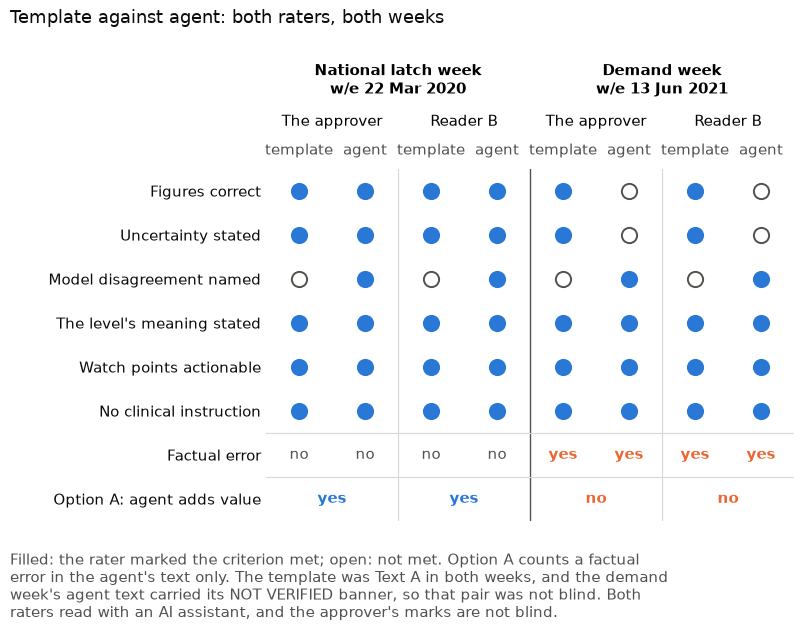

In [43]:
# Figure 7: each rater's marks on both pairs, the template beside the
# agent's text, and option A's verdict under each pair, all from the sheets
# typed from the returned forms.
criteria = {c.field: c.name for c in ap.CRITERIA}
sides = ("template", "agent")
shown_as = {"approver": "The approver", "Reader B": "Reader B"}
pair = {(r.week, r.rater): r for r in ratings}
groups = [(week, rater) for week in tp.WEEKS for rater in tp.RATERS]
columns = [(week, rater, who) for week, rater in groups for who in sides]
rows = [*criteria.values(), "Factual error", "Option A: agent adds value"]
# Sized so that at a 16 cm text column the smallest text prints at 8 pt or
# more.
fig, ax = plt.subplots(figsize=(8, 6.4))
fig.subplots_adjust(left=0.33, right=0.99, top=0.72, bottom=0.17)
ax.set_xlim(-0.5, len(columns) - 0.5)
ax.set_ylim(len(rows) - 0.5, -0.5)
ax.grid(False)
ax.set_xticks([])
ax.set_yticks(range(len(rows)), rows)
ax.tick_params(axis="y", length=0, colors=INK, labelsize=10.5)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
for x, (week, rater, who) in enumerate(columns):
    marks = getattr(pair[(week, rater)], who)
    for y, field in enumerate(criteria):
        met = getattr(marks, field)
        ax.scatter(
            x,
            y,
            s=120,
            facecolor=BLUE if met else "white",
            edgecolor=BLUE if met else MUTED,
            linewidth=1.4,
            zorder=3,
        )
    error = getattr(pair[(week, rater)], f"{who}_factual_error")
    ax.text(
        x,
        len(criteria),
        "yes" if error else "no",
        ha="center",
        va="center",
        color=ORANGE if error else MUTED,
        weight="bold" if error else "normal",
        fontsize=10.5,
    )
    ax.text(
        x, -0.75, who, ha="center", va="bottom", color=MUTED, fontsize=10.5
    )
for n, (week, rater) in enumerate(groups):
    adds = comparison[rater][week]
    ax.text(
        2 * n + 0.5,
        len(rows) - 1,
        "yes" if adds else "no",
        ha="center",
        va="center",
        color=BLUE if adds else ORANGE,
        weight="bold",
        fontsize=10.5,
    )
    ax.text(
        2 * n + 0.5,
        -1.4,
        shown_as[rater],
        ha="center",
        va="bottom",
        fontsize=11,
    )
    if n % 2:
        ax.axvline(2 * n - 0.5, color=GRID, linewidth=0.8, zorder=1)
for n, week in enumerate(tp.WEEKS):
    label = f"{week[0].upper()}{week[1:]}\nw/e {weeks[week].as_of:%d %b %Y}"
    ax.text(
        4 * n + 1.5,
        -2.1,
        label,
        ha="center",
        va="bottom",
        weight="bold",
        fontsize=11,
    )
    if n:
        ax.axvline(4 * n - 0.5, color=MUTED, linewidth=1.0, zorder=1)
for y in (len(criteria) - 0.5, len(criteria) + 0.5):
    ax.axhline(y, color=GRID, linewidth=0.8, zorder=1)
fig.text(
    0.01,
    0.97,
    "Template against agent: both raters, both weeks",
    color=INK,
    fontsize=13,
    va="top",
)
fig.text(
    0.01,
    0.02,
    "Filled: the rater marked the criterion met; open: not met. Option A "
    "counts a factual\nerror in the agent's text only. The template was Text "
    "A in both weeks, and the demand\nweek's agent text carried its NOT "
    "VERIFIED banner, so that pair was not blind. Both\nraters read with an "
    "AI assistant, and the approver's marks are not blind.",
    color=MUTED,
    fontsize=10.5,
)
fig.savefig(
    FIGURES / "fig7_template_comparison.png", dpi=150, bbox_inches="tight"
)
plt.show()

*Figure 7. Template against agent: both raters, both weeks.*

**What the raters found.** Both raters marked each text of both pairs against the six criteria.
Reader B is a person, who read with an AI assistant. The approver's marks were also made with an AI
assistant, and they are not blind: the approver had read every agent brief at approval and was
told the order. Option A decides, week by week and rater by rater, whether the agent's text meets
every criterion the template's meets and at least one more, with no factual error in it.

- **The national latch week: the agent's text adds value, for both raters.** It names the models'
  disagreement, which the template does not, and meets every other criterion the template meets.
- **The demand week: it does not, for both raters.** The agent's text is the refused demand brief.
  Both raters marked its figures not correct, as it is marked NOT VERIFIED, and its uncertainty not
  stated, for its unsupported "Trust them moderately", with a factual error in its claims that
  recent weeks were rising and the forecasts fit them. The checks had already stopped that brief,
  and explaining a demand week only from what the tools return is future work before shadow mode.
- Both raters also marked a factual error in the template's demand-week text: its drift line says
  the forecasts fit recent weeks on the drift rule alone.
- So by option A the agent adds value overall for neither rater, and the two raters agree in each
  week.

Two limits from section 9 apply: the demand week's pair is not blind, since the agent's text carries
its NOT VERIFIED banner, and the seeded order put the template as Text A in both weeks.

## 8. Evaluation summary

**Goals, stated before the evaluation runs.** No threshold moves from this run onwards. G1, G3, G7
and G8 were settled by design tuning in the design probes, run on the same data before this build,
so here they mainly check that the build reproduces the probes' results. G2 is measured here for the first time. G4, G5 and G6 concern the
demand briefs and are measured with them in sections 5 and 6.

| # | Goal | Met if |
|---|---|---|
| G1 | Forecasts a manager can plan with | National MAPE of the primary model as re-selected, at release horizons 1 to 4, on non-shock weeks, within 1 point of the best simple model at every release horizon, the best simple model being the better of seasonal naive and the 4-week moving average at that horizon |
| G2 | Honest uncertainty | 90% to 98% of national actuals inside the primary model's 95% brief range, at release horizons 1 to 4, on the same weeks as G1 |
| G3 | Shocks are caught | The national drift alarm known by Tue 31 Mar 2020; at most 1 false alarm a year nationally |
| G4 | No unchecked number reaches a manager as approved | Every approved brief passes the code figure check again, no "not verified" brief is approved, and the planted wrong figure is rejected |
| G5 | The agent never sets a level | The level in every brief equals the rule's level: a safety invariant, enforced by schema, reported as an invariant, not as a test |
| G6 | Briefs are useful to a person | All but one of the built briefs approved by the approver without a factual edit, and the second reader agreeing with the approver on at least three of four |
| G7 | Raised levels are rare in steady years | Under 10% of outlooks raised in every year except 2020 to 2022, with no floor |
| G8 | A flag tells a manager something | Outlook flags borne out at least twice as often as the outlook base rate, in all years and in the steady years, each; recall reported with no threshold |

Non-shock weeks are the target weeks outside the national drift episodes, first breach to last alarm.
The steady years are 2018 (from July), 2019 and 2023 to 2026. My reading of G2's range, which the
goal leaves open: the forecast times the central 95% of the primary's last 104 released ratios at
that horizon, the same errors the flag reads.

In [44]:
g1_table, g1_met = ev.g1(run)
g2_table, g2_met = ev.g2(run)
g7 = ev.g7(frame)
g8 = ev.g8(frame)
g5 = ap.g5_verdict(result.outcomes)
steady, every = g8["steady_years"], g8["all_years"]
over = {
    y: v["raised_pct_all"]
    for y, v in g7["by_year"].items()
    if y in g7["years_over_10_raised"]
}
verdicts = pd.DataFrame(
    [
        (
            "G1",
            "primary minus best simple model, points, RH1 to RH4: "
            + ", ".join(
                f"{v['primary_minus_best'][0]:+.2f}" for v in g1_table.values()
            ),
            g1_met,
        ),
        (
            "G2",
            "inside the 95% range, %, RH1 to RH4: "
            + ", ".join(f"{v['inside_pct']:.1f}" for v in g2_table.values()),
            g2_met,
        ),
        (
            "G3",
            f"alarm known {g3['known']}; national rising edges by year "
            f"{g3['alarm_rising_edges']}",
            g3["met"],
        ),
        (
            "G4",
            f"{g4['approved_passing_code_check']} of {g4['approved']} "
            "approved briefs pass the code check again; not verified and "
            "approved: "
            f"{g4['not_verified_approved']}; planted figure caught: "
            f"{g4['planted_caught']}",
            g4["met"],
        ),
        (
            "G5",
            f"the rule's level in {g5['level_is_rules']} of the "
            f"{g5['briefs']} briefs written",
            g5["met"],
        ),
        (
            "G6",
            f"{g6['approved_without_factual_edit']} of {g6['built']} approved "
            f"without a factual edit, {g6['needed']} needed; Reader B: "
            f"{reader_b}",
            g6["met"],
        ),
        ("G7", f"over 10% in {over}", g7["met_as_worded"]),
        (
            "G8",
            f"{steady['ratio'][0]:.2f} times the base rate in the steady "
            f"years, {every['ratio'][0]:.2f} in all years",
            g8["met"],
        ),
    ],
    columns=["goal", "result", "met"],
).set_index("goal")
verdicts["verdict"] = verdicts["met"].apply(lambda m: verdict[m])
# G5 is an invariant, not a test, and G7 is reported as narrowly missed and
# not tuned, as ruled.
verdicts.loc["G5", "verdict"] = "holds" if g5["met"] else "broken"
verdicts.loc["G7", "verdict"] = "narrowly missed"
verdicts[["result", "verdict"]]

,result,verdict
goal,,
G1,"primary minus best simple model, points, RH1 to RH4: -0.18, -0.37, -0.55, -0.74",met
G2,"inside the 95% range, %, RH1 to RH4: 96.4, 95.9, 96.1, 95.7",met
G3,"alarm known 2020-03-31; national rising edges by year {2018: 0, 2019: 0, 2023: 1, 2024: 0, 2025: 1, 2026: 1}",met
G4,5 of 5 approved briefs pass the code check again; not verified and approved: 0; planted figure caught: True,met
G5,the rule's level in 7 of the 7 briefs written,holds
G6,"5 of 7 approved without a factual edit, 6 needed; Reader B: 4 of 4 agree",not met
G7,"over 10% in {2018: 10.4, 2023: 10.9, 2024: 11.7}",narrowly missed
G8,"2.54 times the base rate in the steady years, 3.67 in all years",met


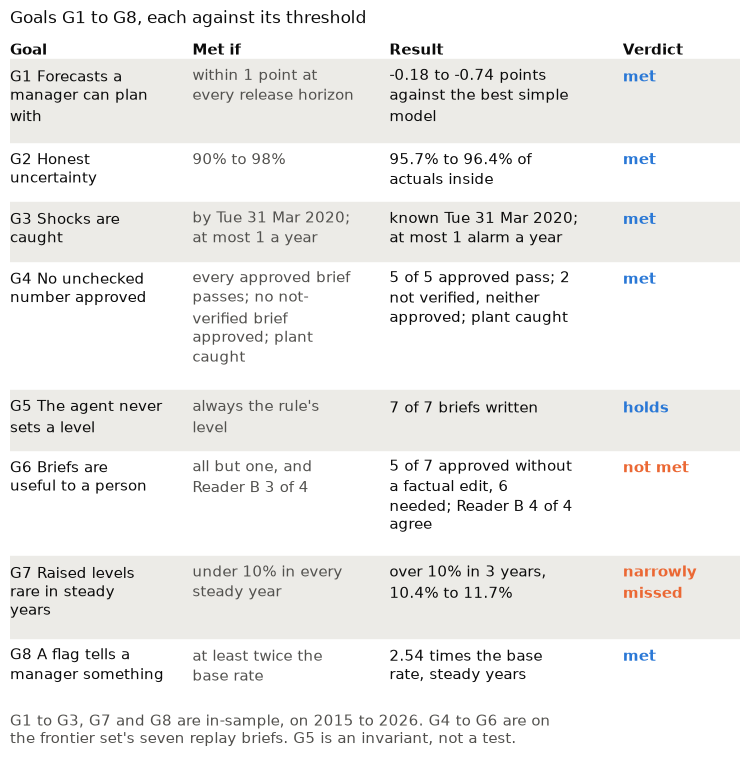

In [45]:
# Figure 5: each goal, its threshold and its verdict, from the cells above.
name = {
    "G1": "Forecasts a manager can plan with",
    "G2": "Honest uncertainty",
    "G3": "Shocks are caught",
    "G4": "No unchecked number approved",
    "G5": "The agent never sets a level",
    "G6": "Briefs are useful to a person",
    "G7": "Raised levels rare in steady years",
    "G8": "A flag tells a manager something",
}
gaps = [v["primary_minus_best"][0] for v in g1_table.values()]
# How many of the briefs that were not verified were approved, in words.
nobody = (
    g4["not_verified_approved"]
    if g4["not_verified_approved"]
    else "neither" if g4["not_verified"] == 2 else "none"
)
inside = [v["inside_pct"] for v in g2_table.values()]
short = {
    "G1": f"{max(gaps):+.2f} to {min(gaps):+.2f} points against the best "
    "simple model",
    "G2": f"{min(inside):.1f}% to {max(inside):.1f}% of actuals inside",
    "G3": f"known {pd.Timestamp(g3['known']):%a %d %b %Y}; at most "
    f"{max(g3['alarm_rising_edges'].values())} alarm a year",
    "G4": f"{g4['approved_passing_code_check']} of {g4['approved']} approved "
    f"pass; {g4['not_verified']} not verified, {nobody} approved; plant "
    f"{'caught' if g4['planted_caught'] else 'not caught'}",
    "G5": f"{g5['level_is_rules']} of {g5['briefs']} briefs written",
    "G6": f"{g6['approved_without_factual_edit']} of {g6['built']} approved "
    f"without a factual edit, {g6['needed']} needed; Reader B "
    f"{'pending' if agreement is None else reader_b}",
    "G7": f"over 10% in {len(over)} years, {min(over.values()):.1f}% to "
    f"{max(over.values()):.1f}%",
    "G8": f"{steady['ratio'][0]:.2f} times the base rate, steady years",
}
threshold = {
    "G1": "within 1 point at every release horizon",
    "G2": "90% to 98%",
    "G3": "by Tue 31 Mar 2020; at most 1 a year",
    "G4": "every approved brief passes; no not-verified brief approved; "
    "plant caught",
    "G5": "always the rule's level",
    "G6": "all but one, and Reader B 3 of 4",
    "G7": "under 10% in every steady year",
    "G8": "at least twice the base rate",
}
good = {"met", "holds"}
# Each column has its own width in characters, and a long cell wraps, so a
# row is as tall as its longest cell. The table is sized so that at a 16 cm
# text column its smallest text prints at 8 pt or more.
columns = [
    ("Goal", 0.0, 19),
    ("Met if", 0.25, 21),
    ("Result", 0.52, 24),
    ("Verdict", 0.84, 10),
]
rows = [
    [f"{goal} {name[goal]}", threshold[goal], short[goal], row["verdict"]]
    for goal, row in verdicts.iterrows()
]
wrapped = [
    [textwrap.wrap(text, width) for text, (_, _, width) in zip(r, columns)]
    for r in rows
]
heights = [max(len(cell) for cell in r) for r in wrapped]
line = 1.0
total = sum(heights) * line + 0.6 * len(rows) + 1.5
fig, ax = plt.subplots(figsize=(7.6, 0.25 * total + 0.6))
fig.subplots_adjust(left=0.02, right=0.98, bottom=0.03)
ax.set_axis_off()
ax.set_xlim(0, 1)
ax.set_ylim(total, 0)
for head, x, _ in columns:
    ax.text(x, 0.5, head, weight="bold", color=INK, va="top", fontsize=11)
y = 1.5
for n, (cells, height) in enumerate(zip(wrapped, heights)):
    if n % 2 == 0:
        ax.add_patch(
            matplotlib.patches.Rectangle(
                (-0.01, y - 0.3), 1.03, height + 0.6, color=BAND, zorder=0
            )
        )
    for k, ((_, x, _), cell) in enumerate(zip(columns, cells)):
        is_verdict = k == len(columns) - 1
        colour = INK if k != 1 else MUTED
        if is_verdict:
            colour = BLUE if rows[n][k] in good else ORANGE
        ax.text(
            x,
            y,
            "\n".join(cell),
            va="top",
            color=colour,
            weight="bold" if is_verdict else "normal",
            linespacing=1.3,
            fontsize=11,
        )
    y += height * line + 0.6
ax.set_title(
    "Goals G1 to G8, each against its threshold",
    loc="left",
    color=INK,
    fontsize=12.5,
)
fig.text(
    0.02,
    0.02,
    "G1 to G3, G7 and G8 are in-sample, on 2015 to 2026. G4 to G6 are on\n"
    "the frontier set's seven replay briefs. G5 is an invariant, not a test.",
    color=MUTED,
    fontsize=10.5,
    va="top",
)
fig.savefig(FIGURES / "fig5_goals_scorecard.png", dpi=150, bbox_inches="tight")
plt.show()

*Figure 5. Goals G1 to G8, each against its threshold.*

**Reading the goals.** Five goals are met, G5 holds, G7 is narrowly missed in three growth years
and G6 is not met because the checks refused both demand briefs.

- **G1, G2, G3 and G8 are met, in-sample.** The primary's national error is within 1 point of the
  best simple model, the better of seasonal naive and the 4-week moving average, at every release
  horizon. It is 0.18 to 0.74 points lower, a measurable difference only at release horizon 4.
  SA-MA on its own scores lower still, 3.47% to 4.57%. Between 95.7% and
  96.4% of national actuals fall inside its 95% range. The drift alarm was known on 31 Mar 2020.
  Outlook flags were borne out 2.54 times as often as the base rate in the steady years.
- **G4 is met and G5 holds**, on the frontier set's seven briefs.
- **G6 is not met.** 5 of the 7 briefs were approved without a factual edit, where 6 are needed.
  The two demand briefs, the only kind raised by a forecast, were the two not verified, so the
  approver could only reject them; none of the five edits was factual, and the fix is future work
  before shadow mode. Reader B, a person, who read with an AI assistant, made the approver's
  decision on all four briefs, so the second half is met.
- **G7 is narrowly missed**, as ruled, and nothing was tuned: 10.4% of outlooks were raised in 2018
  (from July), 10.9% in 2023 and 11.7% in 2024, against under 10%. My reading, which the design probes did not test, is
  that in those growth years attendances ran above the three previous years that set the capacity.
  Shadow mode would test that reading on weeks the design has never seen, before any threshold
  moves.

In [46]:
print(
    "G1, national MAPE % on non-shock weeks, with the primary minus the best "
    "simple model and its 95% interval"
)
display(pd.DataFrame(g1_table).T)
blocks_table, blocks_met = ev.g1(run_blocks)
print(
    f"Sensitivity, SA-MA's index over 52-week blocks: G1 met {blocks_met}; "
    "primary minus best by release horizon: "
    + ", ".join(str(v["primary_minus_best"]) for v in blocks_table.values())
)
print("G2, national actuals inside the primary's 95% brief range")
pd.DataFrame(g2_table).T.astype({"n": int})

G1, national MAPE % on non-shock weeks, with the primary minus the best simple model and its 95% interval


,n,primary,4-week moving average,seasonal naive,SA-MA,best,primary_minus_best,within_1
RH1,441,"[4.04, 3.29, 4.99]",4.22,9.19,3.47,4-week moving average,"[-0.18, -0.65, 0.52]",True
RH2,441,"[4.52, 3.63, 5.59]",4.89,9.19,3.85,4-week moving average,"[-0.37, -0.85, 0.3]",True
RH3,441,"[4.94, 3.93, 6.15]",5.49,9.19,4.2,4-week moving average,"[-0.55, -1.05, 0.1]",True
RH4,441,"[5.31, 4.2, 6.62]",6.05,9.19,4.57,4-week moving average,"[-0.74, -1.22, -0.18]",True


Sensitivity, SA-MA's index over 52-week blocks: G1 met True; primary minus best by release horizon: [0.15, -0.34, 0.84], [-0.13, -0.62, 0.54], [-0.39, -0.89, 0.25], [-0.65, -1.16, -0.06]
G2, national actuals inside the primary's 95% brief range


,n,inside_pct
RH1,441,96.4
RH2,441,95.9
RH3,441,96.1
RH4,441,95.7


In [47]:
alarms, per_year = ev.hospital_false_alarms(run)
print(
    f"G3 nationally: alarm rising edges by steady year "
    f"{g3['alarm_rising_edges']}; new latch episodes "
    f"{g3['new_latch_episodes']}"
)
print(
    f"Beside it, at hospital level: {alarms['rising_edges'].sum()} alarm "
    f"rising edges across {len(alarms)} hospitals in the steady years, "
    f"{per_year:.2f} a hospital a year"
)
alarms.assign(name=alarms["site"].map(NAMES)).sort_values(
    "rising_edges", ascending=False
).head(8)

G3 nationally: alarm rising edges by steady year {2018: 0, 2019: 0, 2023: 1, 2024: 0, 2025: 1, 2026: 1}; new latch episodes {2018: 0, 2019: 0, 2023: 1, 2024: 0, 2025: 1, 2026: 0}
Beside it, at hospital level: 49 alarm rising edges across 30 hospitals in the steady years, 0.28 a hospital a year


,site,rising_edges,name
0,A111H,4,University Hospital Crosshouse
1,A210H,4,University Hospital Ayr
19,R103H,4,The Balfour
10,H103H,3,Caithness General Hospital
21,S314H,3,Royal Infirmary of Edinburgh at Little France
9,G513H,3,Royal Hospital for Children
22,S319H,3,Royal Hospital for Children and Young People
13,L106H,2,University Hospital Monklands


In [48]:
print(
    f"G7, share of hospital outlooks raised by the origin's year; without "
    f"March 2020 to March 2022: {g7['raised_overall']}"
)
pd.DataFrame(g7["by_year"]).T.astype({"hospital_weeks": int, "unlatched": int})

G7, share of hospital outlooks raised by the origin's year; without March 2020 to March 2022: {'without_covid_pct': 10.3, 'with_covid_pct': 8.4, 'flag_rate_unlatched_without_covid_pct': 9.9}


,hospital_weeks,unlatched,flag_rate_unlatched_pct,raised_pct_all,from_flag_pct,from_surge_pct,held_pct,latched_pct
2018,810,754,9.4,10.4,8.8,1.6,0.0,6.9
2019,1560,1457,8.0,9.9,7.4,1.4,1.0,6.6
2020,1560,1156,1.0,1.2,0.7,0.0,0.5,25.9
2021,1560,1543,4.4,4.4,4.4,0.0,0.0,1.1
2022,1560,1520,11.1,11.3,10.8,0.5,0.0,2.6
2023,1590,1518,11.2,10.9,10.7,0.2,0.0,4.5
2024,1560,1531,11.9,11.7,11.7,0.1,0.0,1.9
2025,1560,1511,7.4,7.3,7.2,0.1,0.0,3.1
2026,1230,1184,9.5,9.8,9.1,0.0,0.7,3.7


In [49]:
print(
    "G8, outlook flags: borne out against the outlook base rate, and "
    "recall, with 95% week-block intervals"
)
display(pd.DataFrame({k: g8[k] for k in ("steady_years", "all_years")}).T)
print(
    f"Sensitivity, SA-MA over 52-week blocks: steady-year ratio "
    f"{ev.g8(run_blocks.frame)['steady_years']['ratio']}"
)
by_year = ev.g8_by(frame, frame["year"])
by_year = by_year[by_year["group"] >= 2018].sort_values("group")
cols = [
    "group",
    "outlooks",
    "flags",
    "borne_out_pct",
    "base_rate_pct",
    "recall_pct",
    "ratio",
]
print("By the origin's year")
display(by_year[cols].round(2))
band = frame["series"].map(sizes["band"]).astype(object)
by_band = ev.g8_by(frame, band, steady_only=True)
print(
    "By hospital size band, steady years: rarity buys precision at the cost "
    "of recall"
)
by_band.set_index("group").loc[list(bt.SIZE_BANDS), cols[1:]].round(2)

G8, outlook flags: borne out against the outlook base rate, and recall, with 95% week-block intervals


,weeks,flags,flag_rate_pct,borne_out_pct,base_rate_pct,ratio,recall_pct
steady_years,7805,742,9.5,"[53.8, 45.3, 61.3]","[21.2, 17.4, 24.6]","[2.54, 2.19, 2.95]","[21.0, 17.2, 24.7]"
all_years,12024,989,8.2,"[58.3, 51.2, 64.7]","[15.9, 12.6, 19.3]","[3.67, 3.02, 4.59]","[24.7, 20.4, 29.2]"


Sensitivity, SA-MA over 52-week blocks: steady-year ratio [2.59, 2.25, 3.07]
By the origin's year


,group,outlooks,flags,borne_out_pct,base_rate_pct,recall_pct,ratio
0,2018,754,71,59.15,16.98,26.58,3.48
1,2019,1457,116,59.48,32.44,13.69,1.83
2,2020,1156,11,45.45,1.66,20.83,27.39
3,2021,1543,68,69.12,4.54,41.23,15.22
4,2022,1520,168,75.00,12.80,42.14,5.86
5,2023,1518,170,48.82,17.28,26.27,2.82
6,2024,1531,182,56.59,20.24,27.39,2.80
7,2025,1511,112,54.46,15.44,22.02,3.53
8,2026,1034,91,45.05,23.75,15.47,1.90


By hospital size band, steady years: rarity buys precision at the cost of recall


,outlooks,flags,borne_out_pct,base_rate_pct,recall_pct,ratio
group,,,,,,
under 300,1824,197,52.28,29.50,17.67,1.77
300 to 799,2086,223,52.91,22.76,21.77,2.33
"800 to 1,299",2347,127,52.76,15.45,16.34,3.41
"1,300 and over",1548,195,56.92,18.48,30.75,3.08


**The headline in its two units, each beside its own base rate.** An outlook flag means an unusually
busy week is likely somewhere in the next four, and is set beside the outlook base rate. A week flag
names one target week, and is set beside the week base rate. Precisions are never compared across the
two. Notice is counted in hospital-weeks counted once: a busy week is given notice when any flagged
unlatched outlook covered it, and by the stricter count only when the week's own flag did.

In [50]:
repeats = un.repeat_flags(run)
value = un.value_counts(run, NAMES)


def unit_row(scope):
    u = repeats["units"][scope]
    return {
        "outlook flags borne out, %": u["outlook_flag"]["precision_pct"][0],
        "outlook base rate, %": u["outlook_flag"]["base_rate_pct"][0],
        "week flags right, %": u["week_flag"]["precision_pct"][0],
        "week base rate, %": u["week_flag"]["base_rate_pct"][0],
    }


two_units = pd.DataFrame(
    {s: unit_row(s) for s in ("steady_years", "all_years")}
)
display(two_units)
weeks_steady = value["sites_target_weeks"]["steady_years"]
excess = weeks_steady["excess_over_capacity"]
print(
    f"Steady years, hospital-weeks counted once: "
    f"{weeks_steady['given_notice']} of "
    f"{weeks_steady['busy']} busy weeks given notice; "
    f"{weeks_steady['given_notice_strict']['weeks']} by the week's own flag; "
    f"{excess['flagged_and_busy']['total']:,.0f} of "
    f"{excess['all_busy']['total']:,.0f} extra patients in the weeks given "
    "notice"
)
typical = pd.DataFrame(
    {
        "mean steady year": value["plain"]["typical_steady_year"],
        "range": {
            k: tuple(v) for k, v in value["plain"]["typical_range"].items()
        },
    }
)
print("The mean steady year, over 2019, 2023, 2024 and 2025")
typical

,steady_years,all_years
"outlook flags borne out, %",53.77,58.34
"outlook base rate, %",21.19,15.91
"week flags right, %",27.62,31.84
"week base rate, %",7.78,6.06


Steady years, hospital-weeks counted once: 280 of 713 busy weeks given notice; 197 by the week's own flag; 19,806 of 46,243 extra patients in the weeks given notice
The mean steady year, over 2019, 2023, 2024 and 2025


,mean steady year,range
busy_weeks,142.50,"(101, 204)"
given_notice,57.00,"(42, 71)"
extra_patients_given_notice,4119.40,"(2140.4, 6834.2)"
missed,85.50,"(58, 143)"
extra_patients_missed,5049.55,"(2574.2, 9844.4)"
false_flags,66.00,"(47, 87)"
flags,145.00,"(112, 182)"
given_notice_week_ahead,49.00,"(31, 63)"
extra_patients_week_ahead,3568.60,"(1938.8, 6131.4)"


The mean steady year gave notice of 57.0 of 142.5 busy hospital-weeks (40.0%)
Figure 2's source says the same: True


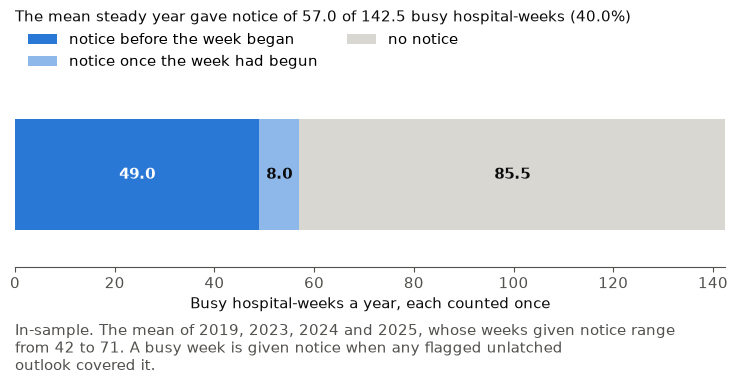

In [51]:
# Figure 6: busy hospital-weeks in the mean steady year, each counted once,
# and how many had notice, from the value counts above.
typ = value["plain"]["typical_steady_year"]
rng = value["plain"]["typical_range"]
share = 100 * typ["given_notice"] / typ["busy_weeks"]
notice = (
    f"the mean steady year gave notice of {typ['given_notice']:.1f} of "
    f"{typ['busy_weeks']:.1f} busy hospital-weeks ({share:.1f}%)"
)
print(notice[0].upper() + notice[1:])
# Figure 2 is drawn from its own Mermaid source, so I hold its wording to
# this one.
figure2 = Path("diagram/value_chain.mmd").read_text(encoding="utf-8")
print(
    "Figure 2's source says the same:", notice in figure2.replace("<br/>", " ")
)
parts = [
    ("notice before the week began", typ["given_notice_week_ahead"], BLUE),
    (
        "notice once the week had begun",
        typ["given_notice"] - typ["given_notice_week_ahead"],
        "#8fb8ea",
    ),
    ("no notice", typ["missed"], GRID),
]
# Sized so that at a 16 cm text column the smallest text prints at 8 pt or
# more.
fig, ax = plt.subplots(figsize=(7.4, 2.4))
fig.subplots_adjust(left=0.02, right=0.98)
left = 0.0
for label, count, colour in parts:
    ax.barh(0, count, left=left, color=colour, height=0.6, label=label)
    ax.text(
        left + count / 2,
        0,
        f"{count:.1f}",
        ha="center",
        va="center",
        color="white" if colour == BLUE else INK,
        weight="bold",
        fontsize=10.5,
    )
    left += count
ax.set_xlim(0, typ["busy_weeks"])
ax.set_ylim(-0.5, 0.5)
ax.set_yticks([])
ax.grid(False)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Busy hospital-weeks a year, each counted once", fontsize=10.5)
ax.tick_params(labelsize=10.5)
ax.legend(
    loc="lower left",
    bbox_to_anchor=(0, 1.0),
    ncol=2,
    frameon=False,
    fontsize=10.5,
)
ax.set_title(
    notice[0].upper() + notice[1:],
    loc="left",
    color=INK,
    pad=44,
    fontsize=11,
)
fig.text(
    0.02,
    -0.12,
    "In-sample. The mean of 2019, 2023, 2024 and 2025, whose weeks given "
    f"notice range\nfrom {rng['given_notice'][0]} to "
    f"{rng['given_notice'][1]}. A busy week is given notice when any flagged "
    "unlatched\noutlook covered it.",
    color=MUTED,
    fontsize=10.5,
    va="top",
)
fig.savefig(FIGURES / "fig6_flag_outcomes.png", dpi=150, bbox_inches="tight")
plt.show()

*Figure 6. Busy hospital-weeks given notice, the mean steady year.*

In [52]:
week = repeats["per_week"]["steady_years"]
rep, first = week["repeated"], week["first"]
print(
    f"Repeated week flags, steady years: right {rep['precision_pct']} % "
    f"against first week flags {first['precision_pct']} %. Clearly more "
    "precise by the rule stated before it was tested: "
    f"{repeats['clearly_more_precise']}, so the graduated response is: "
    f"{repeats['graduated_response']}"
)

Repeated week flags, steady years: right [29.22, 22.16, 35.81] % against first week flags [25.57, 20.73, 31.27] %. Clearly more precise by the rule stated before it was tested: False, so the graduated response is: drop


In [53]:
calibration = ev.calibration(frame)
per_week = calibration["steady_years"]["per_week"]
print(
    f"Steady years: each week's own stated chance averaged "
    f"{per_week['mean_stated']:.3f}, and {per_week['observed']:.1%} of those "
    f"weeks were busy. The flag's chance, the highest of four, against the "
    f"hospital's real-time busy share, Brier skill: "
    f"{calibration['steady_years']['skill_vs_real_time']:.3f}"
)
print("Reliability of each week's own stated chance, steady years")
pd.DataFrame(per_week["reliability"])

Steady years: each week's own stated chance averaged 0.162, and 8.9% of those weeks were busy. The flag's chance, the highest of four, against the hospital's real-time busy share, Brier skill: 0.128
Reliability of each week's own stated chance, steady years


,lo,hi,n,mean_p,observed
0,0.0,0.1,15345,0.033,0.031
1,0.1,0.2,5911,0.145,0.089
2,0.2,0.3,4182,0.245,0.120
3,0.3,0.4,2262,0.349,0.189
4,0.4,0.5,1717,0.443,0.210
5,0.5,0.6,963,0.543,0.232
6,0.6,0.7,468,0.645,0.286
7,0.7,0.8,231,0.744,0.329
8,0.8,0.9,110,0.847,0.409
9,0.9,1.0,31,0.931,0.645


In [54]:
months = ev.by_month(frame)
by_month = pd.DataFrame(months["steady_years"])
by_month.index.name = "month of the origin"
# The September line counts the same eligible steady-year outlooks as the
# table, so the two give one borne-out share.
outlooks, _, steady_mask = ev.scopes(frame)
september = outlooks[steady_mask & (outlooks["month"] == 9)]
unflagged_busy = 100 * september.loc[~september["flag"], "busy"].mean()
print(
    f"September, steady years: {by_month.loc[9, 'flag_rate_pct']}% of "
    "outlooks flagged; outlook flags borne out "
    f"{by_month.loc[9, 'borne_out_pct']}% against {unflagged_busy:.1f}% of "
    "unflagged September outlooks"
)
by_month

September, steady years: 12.8% of outlooks flagged; outlook flags borne out 40.4% against 14.9% of unflagged September outlooks


,flag_rate_pct,share_of_flags_pct,busy_rate_pct,borne_out_pct
month of the origin,,,,
1,6.6,5.1,23.0,50.0
2,15.6,11.6,24.9,51.2
3,6.3,5.9,20.5,47.7
4,10.3,8.6,26.7,37.5
5,11.7,9.7,23.3,50.0
6,4.9,4.4,20.4,57.6
7,7.3,7.1,27.2,71.7
8,12.5,12.4,32.0,69.6
9,12.8,12.0,18.2,40.4


In [55]:
pressure = ev.pressure_match(frame, wide, within4)
print(
    "Raised outlooks in their hospital's worst quarter of 4-hour weeks for "
    "the year, steady years: a weak link, not a pressure measure"
)
pd.Series(pressure, name="value", dtype=object).to_frame()

Raised outlooks in their hospital's worst quarter of 4-hour weeks for the year, steady years: a weak link, not a pressure measure


,value
weeks,8160
raised_pct,9.9
not_borne_out_pct_of_raised,45.6
raised_in_worst_quarter_pct,29.9
chance_pct,25.4
flags_in_worst_quarter_pct,29.8


In [56]:
by_site = ev.level_by_site(frame, sizes, NAMES)
named = ["S314H", "G107H", "G405H"]
shown_sites = pd.concat(
    [by_site.head(5), by_site[by_site["site"].isin(named)]]
).drop_duplicates("site")
print(
    "The demand level by site, steady years: the five most raised, with the "
    "three largest adult EDs beside them"
)
shown_sites.round(1)

The demand level by site, steady years: the five most raised, with the three largest adult EDs beside them


,site,name,mean_weekly,band,outlooks,raised_pct,flags,borne_out_pct,base_rate_pct
0,G513H,Royal Hospital for Children,1425.2,"1,300 and over",277,35.7,79,62.0,13.3
1,N121H,Royal Aberdeen Children's Hospital,342.7,300 to 799,277,26.0,71,42.3,26.7
2,R103H,The Balfour,146.3,under 300,277,21.3,50,60.0,47.2
3,H103H,Caithness General Hospital,188.2,under 300,277,19.5,40,77.5,31.7
4,Y146H,Dumfries & Galloway Royal Infirmary,679.9,300 to 799,277,18.8,52,75.0,20.0
5,G405H,Queen Elizabeth University Hospital,1909.7,"1,300 and over",277,16.6,46,65.2,29.6
22,S314H,Royal Infirmary of Edinburgh at Little France,2362.5,"1,300 and over",277,4.7,6,83.3,22.7
29,G107H,Glasgow Royal Infirmary,1602.1,"1,300 and over",277,0.0,0,NaN,8.7


In [57]:
sites_frame = frame[(frame["series"] != "Scotland") & frame["known"]]
screened = pd.DataFrame(
    {
        y: ev.screened_raise_borne_out(
            g["level"], g["source"], g["latched"], g["busy"]
        )
        for y, g in sites_frame.groupby("year")
        if y in ds.STEADY_YEARS
    }
).T.astype({"screened": int, "raise_borne_out": int})
print(
    "Of the hospital-weeks screened in each steady year, the share carrying "
    "a raise by the rule that was borne out"
)
screened.round(1)

Of the hospital-weeks screened in each steady year, the share carrying a raise by the rule that was borne out


,screened,raise_borne_out,pct
2018,127,54,42.5
2019,219,83,37.9
2023,242,86,35.5
2024,211,103,48.8
2025,161,63,39.1
2026,137,41,29.9


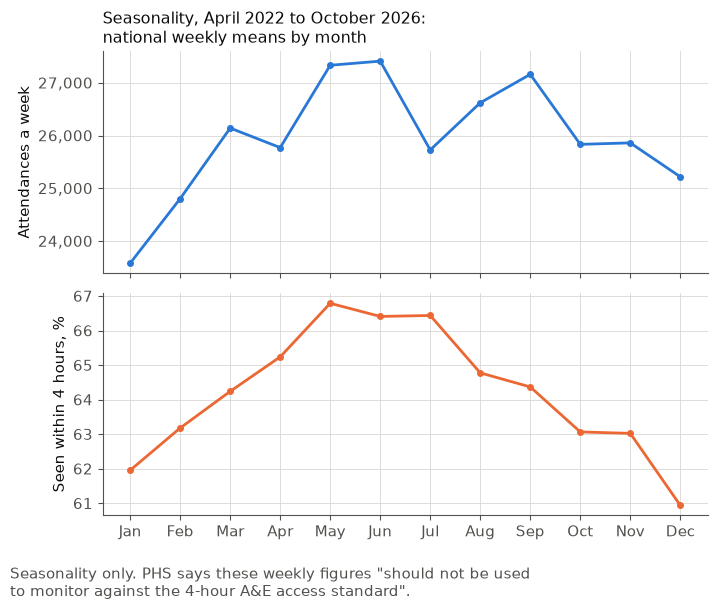

,attendances,within_4h_pct,over_12h
month,,,
1,23582.9,62.0,1923.6
2,24806.8,63.2,1575.3
3,26144.5,64.2,1403.7
4,25774.0,65.2,1194.5
5,27334.6,66.8,1113.6
6,27412.9,66.4,1122.8
7,25730.0,66.4,1014.4
8,26623.5,64.8,1200.3
9,27162.7,64.4,1333.3


In [58]:
profile = ev.month_profile(flagged)
month_names = pd.to_datetime(profile.index, format="%m").strftime("%b")
# Sized so that at a 16 cm text column the smallest text prints at 8 pt or
# more.
fig, (top, bottom) = plt.subplots(2, 1, figsize=(7.2, 5.6), sharex=True)
for ax in (top, bottom):
    ax.tick_params(labelsize=10.5)
top.plot(
    month_names, profile["attendances"], color=BLUE, lw=2, marker="o", ms=4
)
top.set_ylabel("Attendances a week", fontsize=10.5)
top.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
top.set_title(
    "Seasonality, April 2022 to October 2026:\nnational weekly means by month",
    loc="left",
    color=INK,
    fontsize=11.5,
)
bottom.plot(
    month_names, profile["within_4h_pct"], color=ORANGE, lw=2, marker="o", ms=4
)
bottom.set_ylabel("Seen within 4 hours, %", fontsize=10.5)
fig.text(
    0.01,
    -0.02,
    'Seasonality only. PHS says these weekly figures "should not be used\n'
    'to monitor against the 4-hour A&E access standard".',
    color=MUTED,
    fontsize=10.5,
    va="top",
)
fig.tight_layout()
fig.savefig(FIGURES / "fig4_month_chart.png", dpi=150, bbox_inches="tight")
plt.show()
profile.round(1)

*Figure 4. Monthly attendances against 4-hour performance.* Seasonality only: Public Health Scotland
says these weekly figures should not be used to monitor against the 4-hour A&E access standard.

**In-sample.** The bands, the re-selection, SA-MA's two settings, the flag's setting and goals G1,
G3, G7 and G8 were all settled by design tuning on the same 2015 to 2026 data that scores them here.
Every figure in this section is in-sample. Before any go-live, the frozen design would run in shadow
mode on new weekly releases, with every brief written and logged and none acted on.

**Strengths.**

- No unchecked figure reached approval. Every number a manager reads is a tool's value beside its
  label, and the code check caught the planted figure.
- The agent never set a level, and a person decided every brief.
- In the steady years an outlook flag was borne out 53.8% of the time, against 21.2% for an outlook
  without one, and the mean steady year gave notice of 57.0 of 142.5 busy hospital-weeks (40.0%),
  as Figure 6 shows.
- At the COVID alarm the latch held each latched series at the level the flag gave the week before,
  and marked its forecasts untrusted on every brief.

**Failure cases.**

- **COVID, real.** The alarm confirms a shock; it does not warn. The first breach was w/e 15 Mar
  2020, and the alarm at w/e 22 Mar was known on Tue 31 Mar 2020.
- **The planted figure, designed.** The code check caught it at that figure in the frontier set. The
  local sets never wrote a readable draft to plant it in.
- **The demand briefs, real.** The Reviewer refused both for claims no tool result supports, so
  neither could be approved. Explaining a demand week is the part the agent did not do well enough,
  and fixing it is future work before shadow mode.
- **The local backend.** It verified none in either round. In round 1 the text rules refused the 3
  briefs it finished before its budget stopped it, each retry sent blind by a bug in my client that
  round 2 fixed. In round 2 every draft was cut at the output cap, which counts the model's thinking,
  and a retry with thinking turned off is untried.

**The tradeoff between performance, complexity and responsible use.**

- **Performance against complexity.** Outside each series' drift episodes the GRU's interval
  favoured the primary at 16 of the 20 release horizons and the GRU at none. Outside March 2020 to
  March 2022 it favoured the GRU once, at the Queen Elizabeth at release horizon 4, and the primary
  at 7. As stated before the run, the GRU stays a comparator: a yearly refit, three seeds and no
  one-sentence check for a manager.
- **Rarity against recall.** In the steady years 9.5% of outlooks were flagged, and 21.0% of busy
  outlooks were flagged. There are fewer flags, borne out more often, but most busy outlooks are not
  flagged.
- **What the language model adds.** Code sets every number and every level, so the agent adds
  wording, not accuracy. Each brief costs model calls and a person's time to check. In the template
  comparison both raters found the agent's text added value in the national latch week, where it
  named the models' disagreement, and not in the demand week, whose brief the checks had refused
  (Figure 7).
- **The backend.** The frontier model verified 5 of 7 where the local model verified none, for the
  causes above, at the
  cost of money, an outside service and a model that cannot be pinned by digest.

## 9. Limitations and what is simulated

**What is simulated, and who plays which role.** Section 1's table sets out what is simulated or
our own design. That is the simulated capacity, the bands, the latch resets recorded at each review
prompt, the staffing actions and their reply deadlines, the staff acknowledgements and the replay
clock. Nothing is sent; notifications go to an outbox file. In the spot check one person,
the builder, plays three roles: the approver, the unscheduled-care lead and the analytics lead. The
clinical safety reviewer's sign-off is not exercised, because there is no live use. The builder
approving the briefs is itself a limitation, which the second reader, Reader B, a person, who read
with an AI assistant, is there to check; Reader B made the approver's decision on all four briefs.
The approver's marks on the template pairs were made with an AI assistant and are not blind. Every
figure is in-sample, and the tool is advisory: a person decides every action.

**Limitations.** Each rests on an output in this notebook, named after it.

1. **The track-record line drops a figure when there is no past flag.** Ninewells' two briefs say
   only that the hospital has no past flag to judge, though the tool returned how often its
   unflagged outlooks turned busy. The line is code's, fixed before the live run. *Shown in the
   cell below.*
2. **A back-test error sits beside "forecasts untrusted".** Every surge and latch brief gives the
   primary model's back-test error, and a reader could take a low one as a reason to trust a
   forecast. The approved edits add that the error is historical. *Section 5, the briefs as the
   manager sees them; section 6, what each edit changed.*
3. **The Reviewer's reasons are noisy.** Among its problems with Ninewells' demand brief, two points
   say "this is acceptable" and "no issue here" about claims they then pass. *Section 5, the briefs as the manager sees them.*
4. **The local model was not tried with its thinking turned off.** Neither local round verified a
   brief: the first sent its retries blind, and the second spent every draft's 8,192-token output
   cap, which counts the model's thinking. *Section 5, each set's verified count and its
   calls.*
5. **Explaining a demand week overreached.** Both demand briefs, the only kind raised by a forecast,
   were refused for claims no tool result supports, such as a rising trend or a good fit. The
   checks stopped both, and the fix is future work before shadow mode.
   *Section 5, the briefs as the manager sees them.*
6. **The template's drift line makes a claim on the drift rule alone.** "Drift: none. The forecasts
   fit recent weeks." rests on there being no alarm. The agent's similar claim was refused because
   the Reviewer saw no tool result for it. *Section 7, the template briefs; section 5, the
   Reviewer's problems with Lorn & Islands' brief.*
7. **The demand week's pair is not blind.** The agent's text carries its NOT VERIFIED banner and the
   Reviewer's problems, so a rater can tell which text is the agent's. The approver's marks on both
   pairs are not blind either, since the approver had read every agent brief. *Section 7, the pairs
   as the raters see them.*
8. **The seeded order put the template first in both weeks.** The template is Text A in each pair.
   *Section 7, the order kept from the raters.*
9. **A level-2 action holds leave while the forecasts are untrusted.** Edinburgh's surge brief set the hold on
   new leave that code gives every level-2 brief, and it reached the outbox. The approved edits
   removed blanket holds from two latch briefs' watch points. *Section 6, the actions by level,
   what each edit changed and the outbox.*
10. **A range can join the ends of two weeks and pass the code check.** Lorn & Islands' expected
    range runs from the low end for w/e 23 Apr 2023 to the high end for w/e 14 May 2023. Each label
    is true, but the range is no one week's, and the Reviewer did not name it; the approver's note
    did. *Section 5, the briefs as the manager sees them; section 6, each decision's note.*
11. **G6 is not met, and the approver built the system.** Five of the 7 briefs were approved
    without a factual edit, where 6 are needed; the two short are the refused demand briefs of
    limitation 5. Reader B, a person, who read with an AI assistant, made the approver's decision
    on all four briefs, the check on self-approval, but that cannot lift the first half. *Section 6,
    G6.*
12. **Round 1 is not a fair test of the local model.** Its client checked each reply inside the model
    call, so each retry went out blind, without the problems it was refused for. Round 2's client
    read each reply after the call, which fixed it. *Section 5, the
    retries sent blind.*

In [59]:
# Limitation 1: the fixed track-record line beside the tool result it was
# written from, for each brief whose hospital had no past flag.
for o in result.outcomes:
    t = o.facts.track_record
    if t.flags == 0:
        print(
            f'{o.run_id}: the brief says "{br.track_line(t)}" The tool '
            f"returned {t.unflagged_busy} busy of {t.unflagged} unflagged "
            f"outlooks, {t.unflagged_busy_pct:.1f}%."
        )

20200322-T101H: the brief says "This hospital has no past flag to judge." The tool returned 26 busy of 86 unflagged outlooks, 30.2%.
20210613-T101H: the brief says "This hospital has no past flag to judge." The tool returned 29 busy of 136 unflagged outlooks, 21.3%.
